# From JPEG's DCT to Graph Spectral Image Compression

Lessons 1-4 built a graph, found its Laplacian eigenbasis, and projected signals onto it. This
lesson makes a claim that should sound surprising:

> **The discrete cosine transform at the heart of JPEG is already a graph Fourier transform.**
> It is the GFT of a uniformly weighted grid graph. Everything you know about the GFT applies to
> image compression, and "adapting the graph" becomes a concrete, testable idea.

**What this notebook answers, measured rather than asserted:**

1. What does the DCT compute, and why is it useful for images?
2. Which operations actually reduce the number of bits?
3. Why do codecs work with blocks?
4. What are prediction and residuals?
5. How does graph adaptation change the transform?
6. How much compression do the implemented methods achieve on different images?
7. When do graph-description costs erase the benefit of a better transform?

**Audience.** You are comfortable with linear algebra and have just learned the graph Fourier
transform. Image compression is new.

**Scope.** 8-bit grayscale, block transforms, scalar quantization, Huffman entropy coding. We build
two complete teaching codecs that emit real bytes and decode from those bytes alone, and compare
them against actual JPEG files written by Pillow.

> **Bitstream plumbing lives in [`imcodec.py`](imcodec.py)**, so this notebook can show transforms,
> quantizers and symbol construction without drowning in byte handling. Every claim about
> compression here is measured on **actual encoded file sizes**, never on coefficient counts.

### Roadmap

| | Section |
|---|---|
| 1 | The compression problem: what costs bits |
| 2 | The DCT, built from scratch and verified |
| 3 | One block through a JPEG-inspired pipeline |
| 4 | Prediction and residuals |
| 5 | The bridge: the DCT *is* a GFT of the grid graph |
| 6 | An edge-adaptive graph transform |
| 7 | Graph side information, counted honestly |
| 8 | A fair, decodable comparison |
| 9-11 | Experiments, bitrates, and visual inspection |
| 12 | Interpretation, verification, deliverables |


In [1]:
# ============================== CONFIGURATION ==============================
import os, io, json, struct, zlib, hashlib, time, subprocess, sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import scipy.fft as sfft
import pandas as pd
from PIL import Image
from skimage import data

import imcodec as ic                      # the teaching codec (see the file for the container)

SEED = 7
rng = np.random.default_rng(SEED)

# Plot conventions carried over from Lessons 0-4.
plt.rcParams.update({
    "figure.dpi": 110, "figure.constrained_layout.use": True,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
})
C_LINE, C_RED, C_GREEN, C_ORANGE = "#2b6cb0", "#c53030", "#2f855a", "#e07a3f"
GRAY = dict(cmap="gray", vmin=0, vmax=255, interpolation="nearest")   # FIXED 0-255 display

B = 8                     # block size used throughout
OUT_DIR = "out"           # encoded files and reconstructions
os.makedirs(OUT_DIR, exist_ok=True)

import scipy, matplotlib, skimage, PIL
for nm, mod in [("numpy", np), ("scipy", scipy), ("pandas", pd),
                ("matplotlib", matplotlib), ("scikit-image", skimage),
                ("Pillow", PIL)]:
    print(f"{nm:<14} {mod.__version__}")
print(f"\nblock size B = {B}; outputs -> {OUT_DIR}/")

numpy          2.5.3
scipy          1.18.1
pandas         3.0.5
matplotlib     3.11.1
scikit-image   0.26.0
Pillow         12.3.0

block size B = 8; outputs -> out/


In [2]:
# ===================== THE THREE TEST IMAGES, fixed once =====================
def make_synthetic(H=256, W=256):
    """Piecewise smooth: a slow gradient, a straight diagonal boundary, and a
    curved (circular) boundary with a thin ring -- the regime edge-adaptive
    transforms are designed for. Fully deterministic, no randomness."""
    yy, xx = np.mgrid[0:H, 0:W].astype(float)
    img = np.full((H, W), 110.0)
    img += 9 * np.sin(2 * np.pi * xx / W) + 12 * (yy / H)
    img[yy > 0.75 * xx + 40] = 200.0                     # diagonal step
    r = np.hypot(xx - 180, yy - 70)
    img[r < 46] = 55.0                                   # curved boundary
    img[(r >= 46) & (r < 54)] = 150.0                    # thin ring
    img += 6 * np.cos(2 * np.pi * (xx + yy) / 90) * (img < 120)
    return np.clip(img, 0, 255).astype(np.uint8)

demo_img = data.camera()                 # full 512x512; used for the single-block walk-through
CAMERA = data.camera()[::2, ::2].astype(np.uint8)       # 256x256, decimated by 2
GRASS = data.grass()[:256, :256].astype(np.uint8)       # 256x256, top-left crop
SYNTH = make_synthetic()
IMAGES = {"camera": CAMERA, "grass": GRASS, "synthetic": SYNTH}

for nm, im_ in IMAGES.items():
    assert im_.dtype == np.uint8 and im_.shape == (256, 256)
    print(f"{nm:10s} {im_.shape} uint8  range {im_.min():3d}..{im_.max():3d}  "
          f"raw payload {im_.nbytes:,} bytes  "
          f"sha1 {hashlib.sha1(im_.tobytes()).hexdigest()[:12]}")
print()
print("Identical arrays are handed to every method, so nothing in the comparison")
print("depends on differing preprocessing. Provenance is recorded in Section 9.")

camera     (256, 256) uint8  range   1..255  raw payload 65,536 bytes  sha1 c15500962f5a
grass      (256, 256) uint8  range   3..232  raw payload 65,536 bytes  sha1 9b77a8ce4233
synthetic  (256, 256) uint8  range  49..200  raw payload 65,536 bytes  sha1 f47e4e82ccee

Identical arrays are handed to every method, so nothing in the comparison
depends on differing preprocessing. Provenance is recorded in Section 9.


---
## 1. The compression problem

### What an uncompressed image costs

An 8-bit grayscale image is an $H\times W$ array of integers in $[0,255]$. Stored literally, its
**pixel payload** is

$$8HW \ \text{bits} \;=\; HW \ \text{bytes}.$$

That is the number every compression claim in this notebook is measured against. It is *not* the
size of a PNG of the same image: a PNG is already losslessly compressed, so comparing against it
answers a different question ("how much better than PNG?") than the one we are asking ("how much
smaller than raw samples?").

**Colour changes the accounting.** An RGB image stores three 8-bit samples per pixel, so the payload
is $24HW$ bits. Real codecs first convert to a luma/chroma space (Y'C$_\mathrm{B}$C$_\mathrm{R}$)
because the eye is far more sensitive to luminance detail than to colour detail, then **subsample the
chroma planes** — 4:2:0 keeps one C$_\mathrm{B}$ and one C$_\mathrm{R}$ sample per $2\times2$ block
of luma, cutting the chroma payload by four before any transform runs. That alone takes $24HW$ down
to $12HW$. We keep the experiments grayscale so that every remaining bit is attributable to the
transform, quantizer and coder.

### Lossless versus lossy

- **Lossless**: the decoder reconstructs the original array exactly. PNG and lossless JPEG-2000 do
  this. The achievable size is bounded below by the source entropy — you cannot do better than the
  statistics allow.
- **Lossy**: the decoder reconstructs something *close*. Discarding information is what buys the
  large ratios, and the entire design problem becomes choosing **what** to discard.

### A codec is an encoder and a decoder — plus shared conventions

$$\text{image} \;\xrightarrow{\ \text{encoder}\ }\; \text{bits} \;\xrightarrow{\ \text{decoder}\ }\; \text{reconstruction}$$

The decoder gets the bits and **nothing else** except conventions fixed in advance and written into
the standard: block size, scan order, table formats, how a quantized index maps back to a value.
Anything the decoder needs that is not a convention must be **transmitted**, and transmission costs
bits. Section 7 is entirely about the consequences of that sentence.

Following Girod's framing, an encoder has three distinct stages, and only two of them change the
number of bits:

$$\boxed{\text{transform}} \to \boxed{\text{quantizer}} \to \boxed{\text{entropy coder}}$$

> ⚠️ **The transform does not compress.** An invertible transform maps 64 pixel values to 64
> coefficients. Sixty-four numbers in, sixty-four numbers out — and if they are floats, *more* bits
> out than in. What the transform does is **redistribute energy** so that the quantizer can throw
> most coefficients away cheaply and the entropy coder can describe the survivors in few bits. The
> transform *prepares*; the quantizer and the entropy coder *pay*.
>
> 📖 [Girod, EE398A — Introduction](https://web.stanford.edu/class/ee398a/handouts/lectures/00-Introduction.pdf).
> The encoder/decoder block diagram there separates exactly these three stages, and is worth having
> in mind for the rest of this notebook.

The two operations that actually reduce bits:

| Operation | Reversible? | How it saves bits |
|---|---|---|
| **Quantization** | no | maps many distinct values to one index; most become **zero** |
| **Entropy coding** | yes | spends few bits on frequent symbols, many on rare ones |


In [3]:
# The claim above, made concrete on one real 8x8 block.
demo_img = data.camera()
blk = demo_img[120:128, 200:208].astype(np.float64)
C = ic.dct_matrix(B)
F = ic.dct2(blk - 128.0, C)

print("A single 8x8 block of an 8-bit image")
print(f"  pixel payload            : {B*B} samples x 8 bits = {B*B*8} bits")
print(f"  after the DCT            : {F.size} coefficients (float64) = {F.size*64} bits")
print("  -> the transform has made the representation LARGER, not smaller.\n")

q = np.round(F / 16.0)
print(f"  after quantizing (delta=16): {F.size} integers, of which "
      f"{int((q == 0).sum())} are zero ({100*(q==0).mean():.0f}%)")
print(f"  distinct values remaining : {len(np.unique(q))} (from {len(np.unique(np.round(F,6)))})")
print("  -> quantization is where information is destroyed and zeros are created.\n")
print("  entropy coding then spends few bits on the common symbols (zero runs, small")
print("  amplitudes) and more on the rare ones. Section 3 does this for real.")

A single 8x8 block of an 8-bit image
  pixel payload            : 64 samples x 8 bits = 512 bits
  after the DCT            : 64 coefficients (float64) = 4096 bits
  -> the transform has made the representation LARGER, not smaller.

  after quantizing (delta=16): 64 integers, of which 60 are zero (94%)
  distinct values remaining : 4 (from 64)
  -> quantization is where information is destroyed and zeros are created.

  entropy coding then spends few bits on the common symbols (zero runs, small
  amplitudes) and more on the rare ones. Section 3 does this for real.


---
## 2. The discrete cosine transform

### One dimension

For a vector of length $B$, the **orthonormal type-II DCT** matrix is

$$C_{k,n} \;=\; a_k\cos\!\left(\frac{\pi(2n+1)k}{2B}\right),
\qquad a_0=\frac{1}{\sqrt B},\quad a_k=\sqrt{\frac{2}{B}}\ (k>0),$$

with $k,n = 0,\dots,B-1$. Row $k$ is the $k$-th **basis vector**; the transform and its inverse are

$$c = Cx, \qquad x = C^\top c .$$

Every symbol: $x\in\mathbb{R}^B$ is the signal, $c\in\mathbb{R}^B$ its coefficients, $n$ indexes
**position** and $k$ indexes **frequency**. Coefficient $c_k = \langle C_{k,:},\,x\rangle$ is an
inner product — *how much of basis vector $k$ is present in $x$* — which is the same statement as
$\widehat{x}_k = u_k^\top x$ from Lesson 2, with a different basis.

**Spatial frequency** here means variation across pixel *positions*, not across time. $k=0$ is
constant, $k=B-1$ alternates sign at every sample. The $k=0$ coefficient is called the **DC**
coefficient (a name inherited from electrical engineering — direct current, the constant part);
$k\ge1$ are the **AC** coefficients.


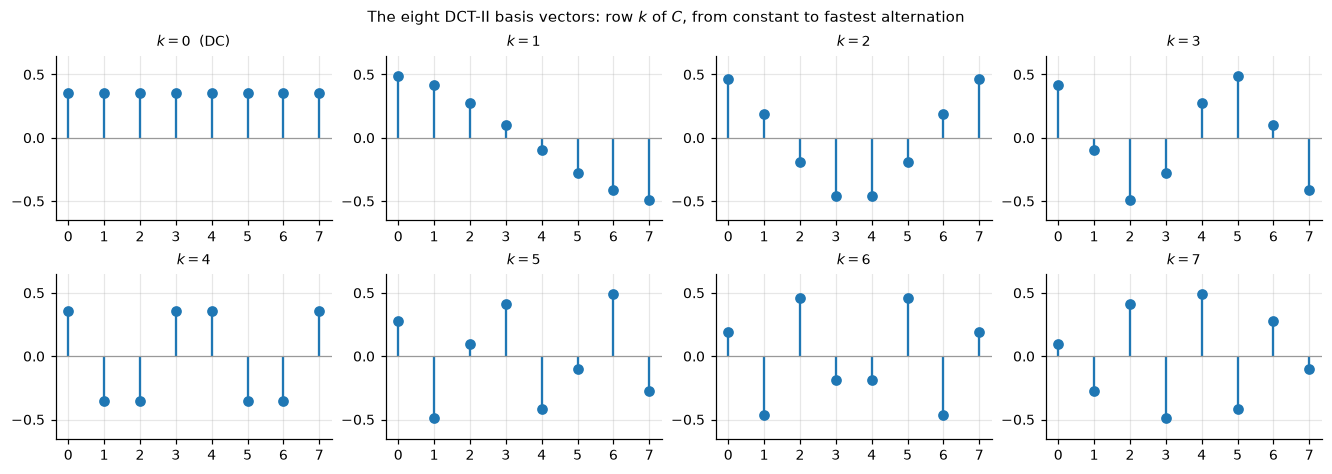

sign changes per basis vector: [0, 1, 2, 3, 4, 5, 6, 7]
-> exactly k, the same 'frequency = how often it flips' reading as Lesson 1's eigenvectors


In [4]:
C = ic.dct_matrix(B)
fig, axes = plt.subplots(2, 4, figsize=(12, 4.2))
for k, ax in enumerate(axes.ravel()):
    ax.stem(np.arange(B), C[k], basefmt=" ")
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_ylim(-0.65, 0.65); ax.set_xticks(range(B))
    ax.set_title(f"$k={k}$" + ("  (DC)" if k == 0 else ""), fontsize=9)
fig.suptitle("The eight DCT-II basis vectors: row $k$ of $C$, from constant to fastest alternation",
             fontsize=10)
plt.show()

print("sign changes per basis vector:",
      [int(np.sum(np.diff(np.sign(C[k])) != 0)) for k in range(B)])
print("-> exactly k, the same 'frequency = how often it flips' reading as Lesson 1's eigenvectors")

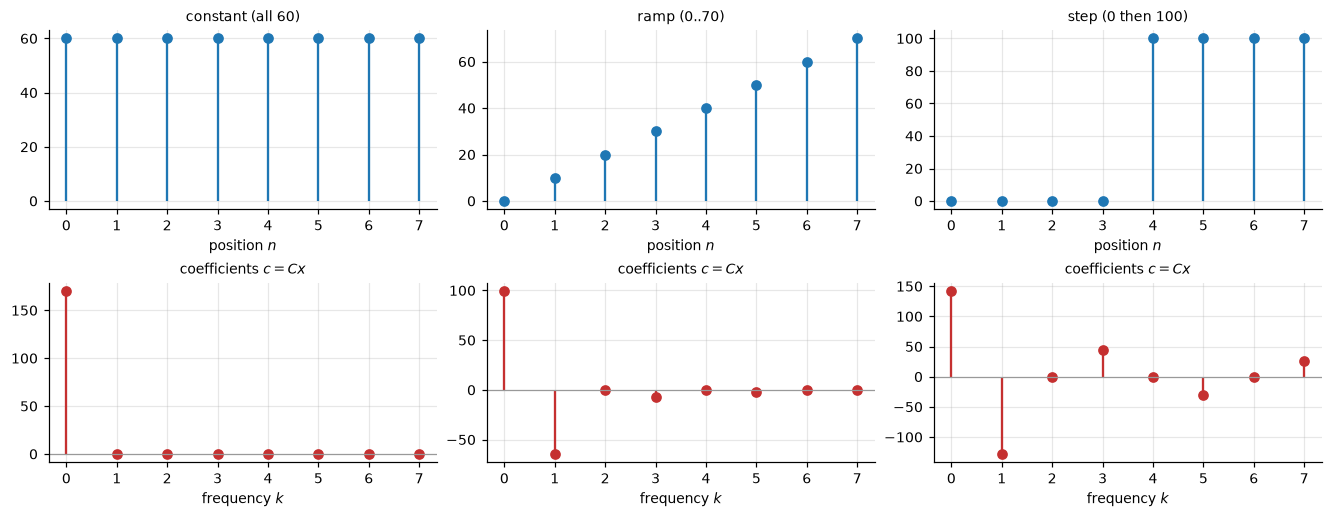

constant (all 60)    -> 1 nonzero coefficient(s); largest |c| at k=0, top-2 hold 100.0% of the energy
ramp (0..70)         -> 5 nonzero coefficient(s); largest |c| at k=0, top-2 hold  99.6% of the energy
step (0 then 100)    -> 5 nonzero coefficient(s); largest |c| at k=0, top-2 hold  91.1% of the energy

Energy compaction: a smooth signal concentrates in few LOW-frequency coefficients.
The step is the hard case -- a discontinuity spreads energy across many k. That is
exactly the situation Section 6's graph adaptation attacks.


In [5]:
signals = {
    "constant (all 60)":      np.full(B, 60.0),
    "ramp (0..70)":           np.linspace(0, 70, B),
    "step (0 then 100)":      np.concatenate([np.zeros(B // 2), np.full(B // 2, 100.0)]),
}
fig, axes = plt.subplots(2, 3, figsize=(12, 4.6))
for j, (name, x) in enumerate(signals.items()):
    c = C @ x
    axes[0, j].stem(np.arange(B), x, basefmt=" ")
    axes[0, j].set_title(name, fontsize=9); axes[0, j].set_xlabel("position $n$")
    axes[1, j].stem(np.arange(B), c, basefmt=" ", linefmt=C_RED, markerfmt="o")
    axes[1, j].set_title(f"coefficients $c=Cx$", fontsize=9); axes[1, j].set_xlabel("frequency $k$")
    axes[1, j].axhline(0, color="0.6", lw=0.8)
plt.show()

for name, x in signals.items():
    c = C @ x
    nz = int(np.sum(np.abs(c) > 1e-9))
    print(f"{name:20s} -> {nz} nonzero coefficient(s); "
          f"largest |c| at k={int(np.argmax(np.abs(c)))}, "
          f"top-2 hold {100*np.sort(c**2)[-2:].sum()/np.sum(c**2):5.1f}% of the energy")
print("\nEnergy compaction: a smooth signal concentrates in few LOW-frequency coefficients.")
print("The step is the hard case -- a discontinuity spreads energy across many k. That is")
print("exactly the situation Section 6's graph adaptation attacks.")

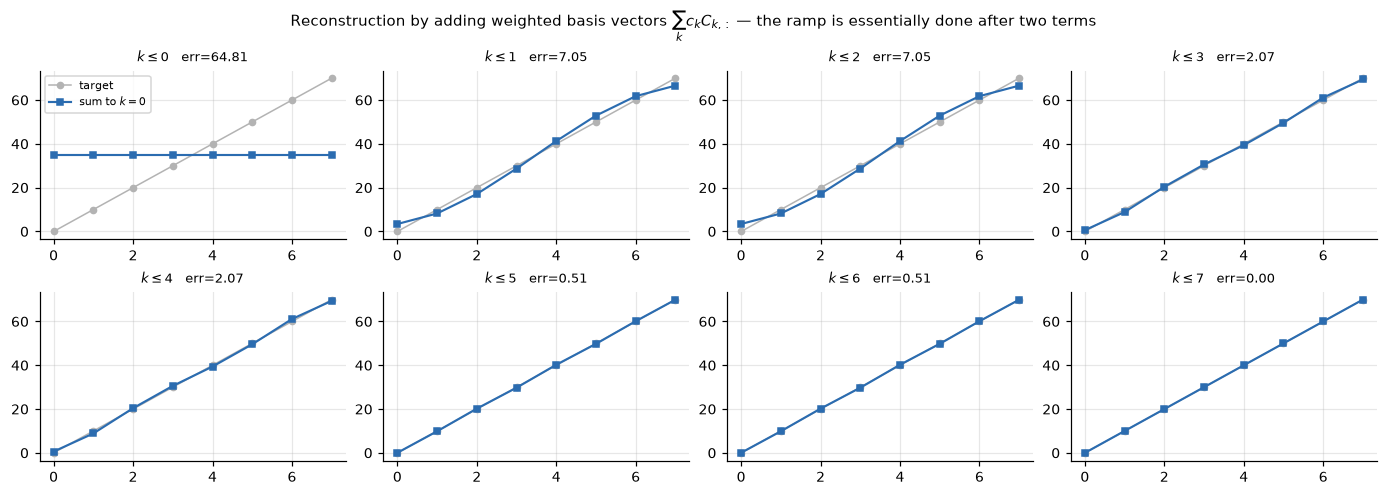

In [6]:
# Reconstruct the ramp one basis vector at a time.
x = signals["ramp (0..70)"]
c = C @ x
fig, axes = plt.subplots(2, 4, figsize=(12.5, 4.4))
partial = np.zeros(B)
for k, ax in enumerate(axes.ravel()):
    partial = partial + c[k] * C[k]
    ax.plot(x, "o-", color="0.7", lw=1, ms=4, label="target")
    ax.plot(partial, "s-", color=C_LINE, lw=1.4, ms=4, label=f"sum to $k={k}$")
    ax.set_title(f"$k \\leq {k}$   err={np.linalg.norm(x-partial):.2f}", fontsize=8.5)
    if k == 0:
        ax.legend(fontsize=7)
fig.suptitle("Reconstruction by adding weighted basis vectors $\\sum_k c_k C_{k,:}$ — "
             "the ramp is essentially done after two terms", fontsize=10)
plt.show()

In [7]:
# --- verification: orthogonality, perfect reconstruction, energy -------------
x = rng.standard_normal(B) * 40 + 120
c = C @ x
print(f"C C^T == I                    : {np.allclose(C @ C.T, np.eye(B))} "
      f"(max off-diagonal {np.abs(C @ C.T - np.eye(B)).max():.2e})")
print(f"C^T C == I                    : {np.allclose(C.T @ C, np.eye(B))}")
print(f"perfect reconstruction        : {np.allclose(C.T @ c, x)} "
      f"(max error {np.abs(C.T @ c - x).max():.2e})")
print(f"energy preserved (Parseval)   : {np.allclose(x @ x, c @ c)}   "
      f"||x||^2={x @ x:.4f}  ||c||^2={c @ c:.4f}")
print(f"matches scipy.fft.dct(norm='ortho'): "
      f"{np.allclose(c, sfft.dct(x, type=2, norm='ortho'))}")
print("\nThis is the same orthonormal-basis story as Lesson 2: an orthonormal transform")
print("rotates the coordinate system and preserves length. It cannot compress on its own.")

C C^T == I                    : True (max off-diagonal 1.40e-15)
C^T C == I                    : True
perfect reconstruction        : True (max error 3.27e-13)
energy preserved (Parseval)   : True   ||x||^2=112773.0614  ||c||^2=112773.0614
matches scipy.fft.dct(norm='ortho'): True

This is the same orthonormal-basis story as Lesson 2: an orthonormal transform
rotates the coordinate system and preserves length. It cannot compress on its own.


### Two dimensions, separably

An $8\times8$ block is transformed by applying the 1-D DCT to every row and then to every column,
which in matrix form is

$$F = C X C^\top, \qquad X = C^\top F C .$$

The $(u,v)$ entry of $F$ is the coefficient of the **basis image**

$$\Phi_{u,v} \;=\; C_{u,:}^{\ \top} C_{v,:} \qquad (\text{an outer product of two 1-D basis vectors}),$$

so the 64 basis images are all products of a vertical cosine with a horizontal cosine. $u$ counts
vertical oscillations and $v$ horizontal ones; $(0,0)$ is flat (the DC basis image) and $(7,7)$ is
the fastest checkerboard.

> 📖 [Strang, *The Discrete Cosine Transform* (1999)](https://math.mit.edu/~gs/papers/dct.pdf)
> derives these bases from the eigenvectors of a second-difference matrix and explains the
> **boundary conditions** that distinguish the DCT types — which is exactly the graph statement
> Section 5 makes precise.
>
> 📖 [Girod, EE398A — Transform Coding](https://web.stanford.edu/class/ee398a/handouts/lectures/07-TransformCoding.pdf)
> for why energy compaction is the property that matters for coding.


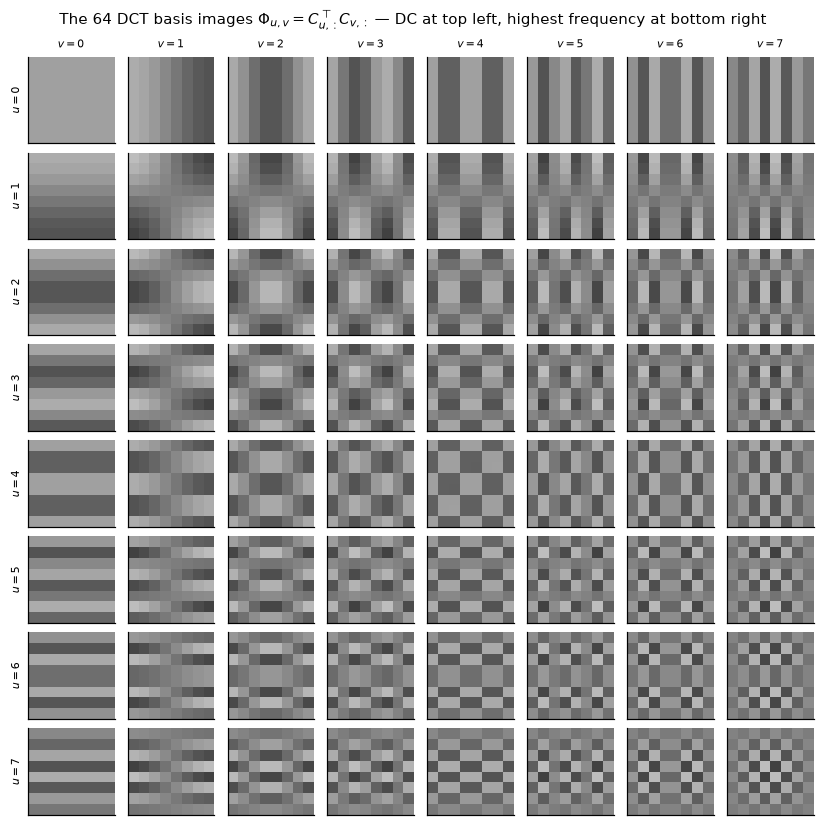

basis images orthonormal as 64 vectors: True
2-D transform matches scipy.fft.dctn : True


In [8]:
basis = np.zeros((B, B, B, B))
for u in range(B):
    for v in range(B):
        basis[u, v] = np.outer(C[u], C[v])

fig, axes = plt.subplots(B, B, figsize=(7.4, 7.4))
for u in range(B):
    for v in range(B):
        ax = axes[u, v]
        ax.imshow(basis[u, v], cmap="gray", vmin=-0.5, vmax=0.5, interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if u == 0: ax.set_title(f"$v={v}$", fontsize=7)
        if v == 0: ax.set_ylabel(f"$u={u}$", fontsize=7)
fig.suptitle("The 64 DCT basis images $\\Phi_{u,v}=C_{u,:}^\\top C_{v,:}$ — "
             "DC at top left, highest frequency at bottom right", fontsize=10)
plt.show()

Phi = basis.reshape(64, 64)
print(f"basis images orthonormal as 64 vectors: "
      f"{np.allclose(Phi @ Phi.T, np.eye(64))}")
print(f"2-D transform matches scipy.fft.dctn : "
      f"{np.allclose(ic.dct2(blk, C), sfft.dctn(blk, type=2, norm='ortho'))}")

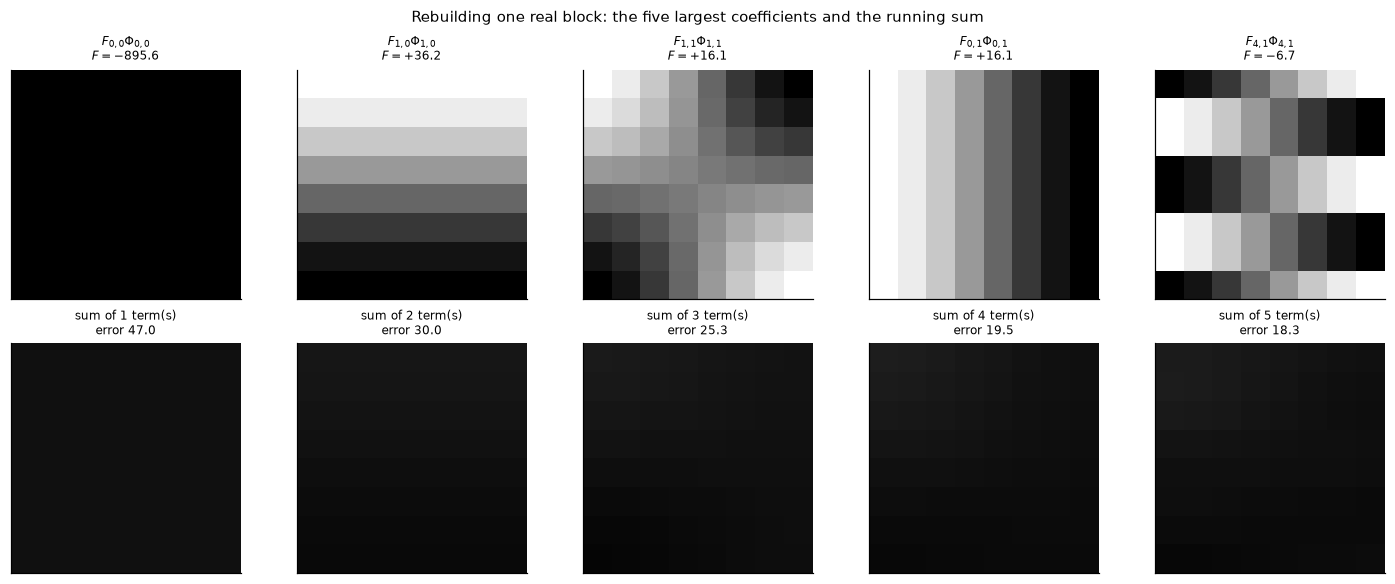

fraction of block energy in the largest  1 coefficient:  99.7%
                                  largest  5          : 100.0%
                                  largest 10          : 100.0%

That concentration is 'energy compaction', and it is the whole reason a transform
is applied before quantization: most coefficients are already nearly zero.


In [9]:
X = demo_img[120:128, 200:208].astype(np.float64) - 128.0
F = ic.dct2(X, C)
order = np.argsort(-np.abs(F).ravel())          # strongest contributions first
fig, axes = plt.subplots(2, 5, figsize=(13, 5.2))
running = np.zeros((B, B))
for j in range(5):
    u, v = divmod(order[j], B)
    contrib = F[u, v] * basis[u, v]
    running = running + contrib
    axes[0, j].imshow(contrib, cmap="gray", interpolation="nearest")
    axes[0, j].set_title(f"$F_{{{u},{v}}}\\Phi_{{{u},{v}}}$\n$F={F[u,v]:+.1f}$", fontsize=8)
    axes[1, j].imshow(running + 128, **GRAY)
    axes[1, j].set_title(f"sum of {j+1} term(s)\nerror {np.linalg.norm(X-running):.1f}", fontsize=8)
    for ax in (axes[0, j], axes[1, j]):
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Rebuilding one real block: the five largest coefficients and the running sum",
             fontsize=10)
plt.show()

e = np.sort(F.ravel() ** 2)[::-1]
print(f"fraction of block energy in the largest  1 coefficient: {e[0]/e.sum():6.1%}")
print(f"                                  largest  5          : {e[:5].sum()/e.sum():6.1%}")
print(f"                                  largest 10          : {e[:10].sum()/e.sum():6.1%}")
print("\nThat concentration is 'energy compaction', and it is the whole reason a transform")
print("is applied before quantization: most coefficients are already nearly zero.")

---
## 3. One block through a JPEG-inspired pipeline

Baseline sequential JPEG, in the order the standard applies it:

1. **Divide** the image into non-overlapping $8\times8$ blocks.
2. **Level shift**: subtract 128, moving $[0,255]$ to $[-128,127]$.
3. **Forward DCT** on each block.
4. **Quantize** each coefficient by its own step size.
5. **Zigzag scan** the $8\times8$ array into a length-64 vector, low frequency first.
6. **Differentially code the DC** coefficient against the previous block's DC.
7. **Run-length code the AC** coefficients as (zero-run, amplitude-size) pairs.
8. **Entropy code** the resulting symbols with Huffman tables.

### Why blocks?

Three reasons, all practical:

- **Local adaptation.** Image statistics change across a picture — sky is smooth, foliage is not. A
  transform over the whole image would have to compromise; a per-block transform adapts.
- **Computation.** An $N\times N$ transform costs $O(N^2)$ per output. Blocks make it $O(B^2)$ per
  block with $B=8$ fixed, so cost grows linearly in pixels.
- **Error containment and random access.** A corrupted or re-sent region affects only its blocks,
  and a decoder can start anywhere.

The price is **blocking artifacts**: each block is quantized independently, so at low rates the
reconstructions do not agree across block boundaries and the $8\times8$ grid becomes visible. We
show this later at strong compression.

### Quantization, precisely

$$q_{u,v} = \operatorname{round}\!\left(\frac{F_{u,v}}{Q_{u,v}}\right),
\qquad \widetilde F_{u,v} = Q_{u,v}\,q_{u,v}.$$

The encoder transmits the **integers** $q_{u,v}$. The decoder multiplies them back by the same
$Q_{u,v}$, which it must therefore know — in JPEG the quantization table is written into the file
header. Larger steps mean coarser reconstruction, larger error, and more coefficients rounding to
**zero**, which is what the run-length coder exploits.


In [10]:
# --- one block, every stage, with the actual numbers -------------------------
r0, c0 = 120, 200
orig = demo_img[r0:r0 + B, c0:c0 + B].astype(np.int64)
cent = orig - 128
F = ic.dct2(cent.astype(float), C)
Q = ic.JPEG_LUMA_Q
qf = np.round(F / Q).astype(np.int64)
Fr = qf * Q
rec = np.clip(np.round(ic.idct2(Fr, C) + 128), 0, 255).astype(np.int64)
err = orig - rec

def show(name, A, fmt="{:5d}"):
    print(f"\n{name}")
    for row in A:
        print("   " + " ".join(fmt.format(v) if not isinstance(v, float) else f"{v:7.1f}"
                               for v in row))

show(f"1-2. original samples, block at row {r0}, col {c0}", orig)
show("     level-shifted (x - 128)", cent)
show("3.   DCT coefficients F (rounded for display)", np.round(F).astype(np.int64))
show("4a.  quantization table Q (T.81 Annex K luminance)", Q.astype(np.int64))
show("4b.  quantized indices q = round(F/Q)   <-- THESE are transmitted", qf)
show("4c.  dequantized Ftilde = Q*q", Fr.astype(np.int64))
show("     reconstructed pixels", rec)
show("     error (original - reconstructed)", err)
print(f"\nzeros among the 64 quantized indices: {int((qf==0).sum())}/64 "
      f"({100*(qf==0).mean():.0f}%)")
print(f"block MSE {np.mean(err.astype(float)**2):.2f}, max |error| {np.abs(err).max()}")


1-2. original samples, block at row 120, col 200
      27    26    27    28    19    20    16    20
      34    34    28    25    17    15    15    16
      24    22    21    17    17    17    14    16
      21    18    15    13    13    13    14    17
      18    13    11    13    14    13    15    15
      14    13    14    12    12    14    14    12
      12    12    13    12    12    11     9    11
       9    10    10     9    10     9    10    12

     level-shifted (x - 128)
    -101  -102  -101  -100  -109  -108  -112  -108
     -94   -94  -100  -103  -111  -113  -113  -112
    -104  -106  -107  -111  -111  -111  -114  -112
    -107  -110  -113  -115  -115  -115  -114  -111
    -110  -115  -117  -115  -114  -115  -113  -113
    -114  -115  -114  -116  -116  -114  -114  -116
    -116  -116  -115  -116  -116  -117  -119  -117
    -119  -118  -118  -119  -118  -119  -118  -116

3.   DCT coefficients F (rounded for display)
    -896    16     6    -2     2     0     2    -1
      

In [11]:
# --- 5. zigzag, 6-7. run-length symbols, with an end-of-block -----------------
zz = ic.zigzag_order(B)
scan = qf.ravel()[zz]
print("5. zigzag scan order visits the block low-frequency first:")
grid = np.empty((B, B), dtype=int)
for pos, flat in enumerate(zz):
    grid[flat // B, flat % B] = pos
show("   scan position of each (u,v)", grid, "{:3d}")
print(f"\n   coefficients in scan order:\n   {scan.tolist()}")

dc_prev = 0
(dsym, dextra), acs, ace, _ = ic._block_symbols(scan, dc_prev)
print(f"\n6. DC: value {scan[0]}, previous block DC {dc_prev} -> difference {scan[0]-dc_prev}")
print(f"   category (bits needed) = {dsym}, then {dsym} raw amplitude bits")
print("\n7. AC symbols, each byte packed as (run << 4) | size:")
k = 1
for s, e in zip(acs, ace):
    if s == 0x00:
        print(f"   0x00  EOB          -> 'all remaining {64-k} coefficients are zero'")
    elif s == 0xF0:
        print(f"   0xF0  ZRL          -> 'sixteen zeros'"); k += 16
    else:
        run, sz = s >> 4, s & 0xF
        k += run
        print(f"   0x{s:02X}  run={run:2d} size={sz}  -> {run} zero(s), then value "
              f"{scan[k]:+4d} in {sz} bits")
        k += 1
raw_bits = 64 * 8
sym_bits = sum(4 for _ in acs) + dsym
print(f"\n   64 coefficients became {len(acs)} AC symbols plus one DC symbol.")
print("   Zeros are never coded individually -- they are collapsed into runs, and the")
print("   tail is replaced by a single EOB. That is why quantization's zeros are valuable.")

5. zigzag scan order visits the block low-frequency first:

   scan position of each (u,v)
     0   1   5   6  14  15  27  28
     2   4   7  13  16  26  29  42
     3   8  12  17  25  30  41  43
     9  11  18  24  31  40  44  53
    10  19  23  32  39  45  52  54
    20  22  33  38  46  51  55  60
    21  34  37  47  50  56  59  61
    35  36  48  49  57  58  62  63

   coefficients in scan order:
   [-56, 1, 3, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

6. DC: value -56, previous block DC 0 -> difference -56
   category (bits needed) = 6, then 6 raw amplitude bits

7. AC symbols, each byte packed as (run << 4) | size:
   0x01  run= 0 size=1  -> 0 zero(s), then value   +1 in 1 bits
   0x02  run= 0 size=2  -> 0 zero(s), then value   +3 in 2 bits
   0x11  run= 1 size=1  -> 1 zero(s), then value   +1 in 1 bits
   0x01  run= 0 size=1  -> 0 zero(s), 

> ⚠️ **This is a JPEG-*inspired* codec, not a JPEG encoder.** It follows the same pipeline and uses
> T.81's example quantization table and (run, size) symbol structure, but it does not emit a
> standards-compliant JPEG bitstream — no markers, no restart intervals, no APP segments, and our
> Huffman tables are written in our own container. Section 8 compares against **real** JPEG files
> written by Pillow, which is a different and necessary reference.
>
> 📖 [Wallace, *The JPEG Still Picture Compression Standard*](https://www.ijg.org/files/Wallace.JPEG.pdf)
> for the readable overview; [Girod, EE398A — JPEG](https://web.stanford.edu/class/ee398a/handouts/lectures/08-JPEG.pdf)
> for the coding-theory framing; [ITU-T T.81](https://www.w3.org/Graphics/JPEG/itu-t81.pdf) for the
> normative text — **Annex A** covers the transform and quantization, **Annex F** sequential
> Huffman coding, and **Annex K** supplies the example tables used above.


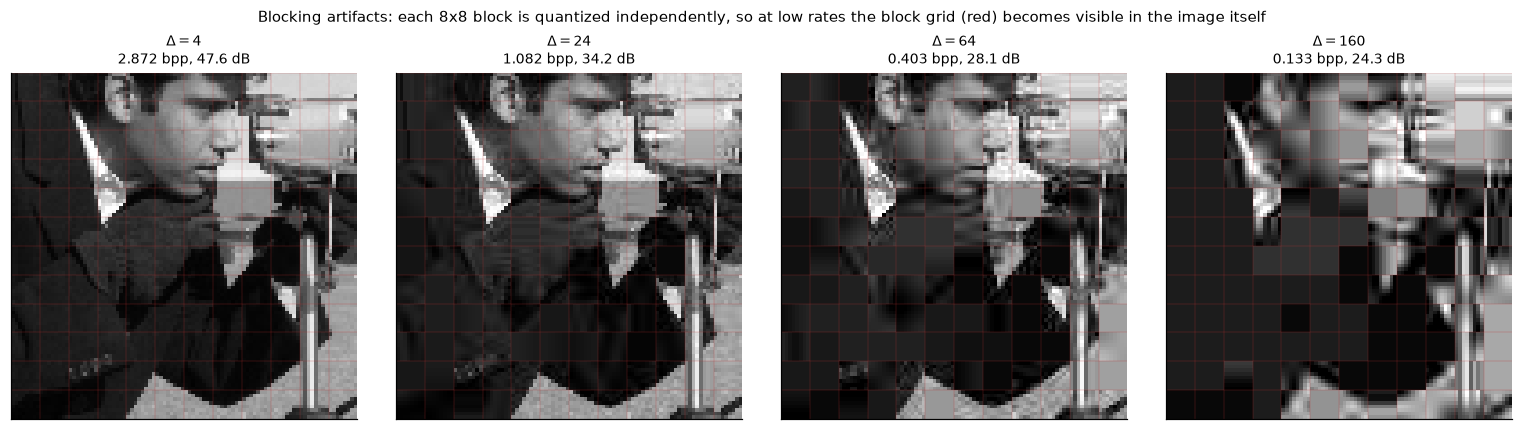

In [12]:
# Blocking artifacts: the same image at increasing quantizer step.
img_demo = demo_img[::2, ::2].astype(np.uint8)
H0, W0 = img_demo.shape
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, d in zip(axes, [4.0, 24.0, 64.0, 160.0]):
    by = ic.encode(img_demo, method="dct", delta=d)
    rec_img = ic.decode(by)
    ax.imshow(rec_img[64:160, 64:160], **GRAY)
    for g in range(0, 96, B):
        ax.axhline(g - 0.5, color=C_RED, lw=0.3, alpha=0.55)
        ax.axvline(g - 0.5, color=C_RED, lw=0.3, alpha=0.55)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(f"$\\Delta={d:g}$\n{ic.bpp(len(by),H0,W0):.3f} bpp, "
                 f"{ic.psnr(img_demo,rec_img):.1f} dB", fontsize=9)
fig.suptitle("Blocking artifacts: each 8x8 block is quantized independently, so at low rates "
             "the block grid (red) becomes visible in the image itself", fontsize=10)
plt.show()

---
## 4. Prediction and residuals

### Two different things both called "prediction"

JPEG already does one kind, and it is easy to confuse them:

| | What is predicted | From what | Where it appears |
|---|---|---|---|
| **DC differential coding** (JPEG, §3 step 6) | the single **quantized DC** coefficient | the previous block's quantized DC | inside the entropy coder |
| **Spatial intra prediction** (this section) | the **whole block of pixels** | already-reconstructed neighbouring pixels | before the transform |

The first is a cheap trick on one number. The second changes *what signal is transformed at all*,
and it is the architecture that HEVC, AV1 and VVC are built around.

### Predictive transform coding

$$r = x - p, \qquad c = Tr, \qquad \widehat{x} = p + T^\top \widetilde{c},$$

where $p$ is a prediction the **decoder can reproduce exactly**, $r$ the **residual**,
$\widetilde c$ the quantized coefficients. This is Figure 4.2 of the book: prediction, transform,
then quantization and entropy coding, with the decoder mirroring all three.

**The closed loop is the subtle part.** The encoder must predict from the *reconstructed* neighbours,
not the original ones, because the reconstructed values are all the decoder will have. If the encoder
predicted from originals, encoder and decoder would drift apart and the error would compound down the
image. Our `predict_block` therefore reads from the encoder's own running reconstruction buffer.

**Our predictor** is deliberately simple and causal: the mean of the reconstructed pixel row directly
above the block and the reconstructed pixel column directly to its left. At the top row only the left
column is available, at the left column only the row above, and at the very first block neither, so
the prediction is the mid-level 128. All arithmetic is signed float; rounding to integers and
clipping to $[0,255]$ happen at exactly one place, identically at both ends.

> 📖 Chapter 4, §4.1.1 and Figure 4.2 (printed p. 77) of *Graph Spectral Image Processing*, and
> [Girod, EE398A — Predictive Coding](https://web.stanford.edu/class/ee398a/handouts/lectures/06-Prediction.pdf).


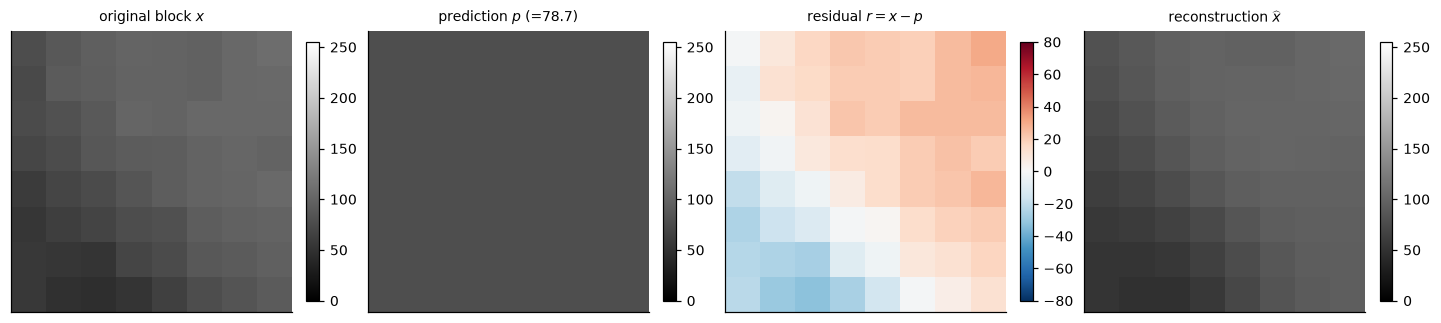

block mean 84.8, prediction 78.7, residual mean +6.11
reconstruction error: max |x - xhat| = 8


In [13]:
# --- one block: original, prediction, residual, reconstruction ---------------
img_demo = demo_img[::2, ::2].astype(np.uint8)
H0, W0 = img_demo.shape
delta_demo = 16.0

# run the encoder far enough to have a real reconstruction buffer, then look at one block
padded, _, _ = ic.pad_to_blocks(img_demo.astype(float), B)
nbr, nbc = padded.shape[0] // B, padded.shape[1] // B
recon_buf = np.zeros_like(padded)
target = (10, 12)                                   # block row, block col to display
for br in range(nbr):
    for bc in range(nbc):
        blkf = padded[br*B:(br+1)*B, bc*B:(bc+1)*B]
        p = ic.predict_block(recon_buf, br, bc, B)
        rres = blkf - p
        Fp = ic.dct2(rres, C)
        qp = np.round(Fp / delta_demo) * delta_demo
        rr = ic.idct2(qp, C) + p
        recon_buf[br*B:(br+1)*B, bc*B:(bc+1)*B] = np.clip(np.round(rr), 0, 255)
        if (br, bc) == target:
            keep = (blkf.copy(), p.copy(), rres.copy(), recon_buf[br*B:(br+1)*B, bc*B:(bc+1)*B].copy())
blkf, p, rres, rrec = keep

fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for ax, (A, t, kw) in zip(axes, [
        (blkf, "original block $x$", GRAY),
        (p, f"prediction $p$ (={p[0,0]:.1f})", GRAY),
        (rres, "residual $r = x - p$", dict(cmap="RdBu_r", vmin=-80, vmax=80, interpolation="nearest")),
        (rrec, "reconstruction $\\widehat{x}$", GRAY)]):
    im = ax.imshow(A, **kw); ax.set_title(t, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.show()
print(f"block mean {blkf.mean():.1f}, prediction {p[0,0]:.1f}, residual mean {rres.mean():+.2f}")
print(f"reconstruction error: max |x - xhat| = {np.abs(blkf-rrec).max():.0f}")

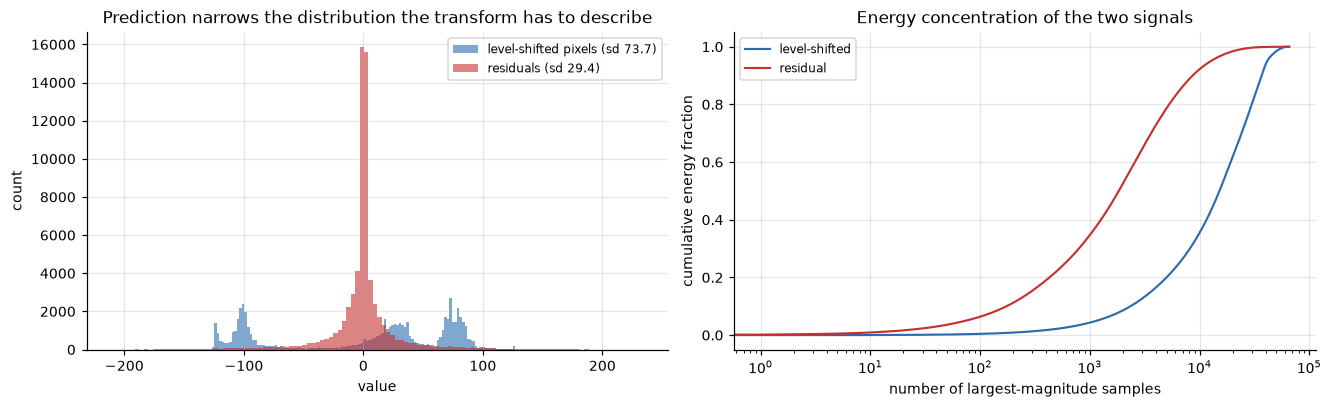

variance of level-shifted pixels :    5432.9
variance of residuals            :     864.2   (15.9% of the original)


In [14]:
# --- does prediction actually change the signal statistics? ------------------
pix, res = [], []
recon_buf = np.zeros_like(padded)
for br in range(nbr):
    for bc in range(nbc):
        blkf = padded[br*B:(br+1)*B, bc*B:(bc+1)*B]
        p = ic.predict_block(recon_buf, br, bc, B)
        pix.append((blkf - 128.0).ravel()); res.append((blkf - p).ravel())
        Fp = np.round(ic.dct2(blkf - p, C) / delta_demo) * delta_demo
        recon_buf[br*B:(br+1)*B, bc*B:(bc+1)*B] = np.clip(
            np.round(ic.idct2(Fp, C) + p), 0, 255)
pix = np.concatenate(pix); res = np.concatenate(res)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(pix, bins=120, alpha=0.6, color=C_LINE, label=f"level-shifted pixels (sd {pix.std():.1f})")
axes[0].hist(res, bins=120, alpha=0.6, color=C_RED, label=f"residuals (sd {res.std():.1f})")
axes[0].set_xlabel("value"); axes[0].set_ylabel("count"); axes[0].legend(fontsize=8)
axes[0].set_title("Prediction narrows the distribution the transform has to describe")
for lbl, arr, col in [("level-shifted", pix, C_LINE), ("residual", res, C_RED)]:
    e = np.sort(arr ** 2)[::-1]
    axes[1].plot(np.cumsum(e) / e.sum(), lw=1.4, color=col, label=lbl)
axes[1].set_xscale("log"); axes[1].set_xlabel("number of largest-magnitude samples")
axes[1].set_ylabel("cumulative energy fraction"); axes[1].legend(fontsize=8)
axes[1].set_title("Energy concentration of the two signals")
plt.show()

print(f"variance of level-shifted pixels : {pix.var():9.1f}")
print(f"variance of residuals            : {res.var():9.1f}   "
      f"({100*res.var()/pix.var():.1f}% of the original)")

**Why prediction can help.** If $p$ is close to $x$, the residual has much smaller variance, so at a
fixed quantizer step more coefficients round to zero and the entropy coder sees a more skewed
distribution. The transform is then describing *what the prediction missed* rather than the image
itself.

**Why a predictor can fail, and why ours mostly does.** Our predictor supplies a single **constant**
per block. But a constant is exactly what the DC coefficient already represents — and JPEG *already*
codes DC differentially against the previous block. So this predictor is largely **redundant with
machinery the codec already has**, and Section 9 measures almost no rate saving from it. Worse, it
introduces a closed loop: each block's prediction depends on earlier reconstructions, so quantization
error propagates spatially, and a transform that is slightly worse per block compounds down the image.

A predictor earns its place only when it captures structure the transform cannot cheaply represent —
directional edges continuing from the neighbours, for instance, which is what real intra prediction
modes do. We keep the simple one because its *failure* is instructive and measured rather than
assumed.


---
## 5. The bridge — the DCT is already a GFT

### One dimension: the path graph

Take $B$ pixels in a row and join each to its immediate neighbours with weight 1. Endpoints have
degree 1, interior nodes degree 2. The combinatorial Laplacian $L = D - W$ is

$$L_u=\begin{pmatrix}1&-1&&&\\-1&2&-1&&\\&\ddots&\ddots&\ddots&\\&&-1&2&-1\\&&&-1&1\end{pmatrix}.$$

**Claim.** The eigenvectors of $L_u$ are exactly the DCT-II basis vectors, with eigenvalues

$$\lambda_k \;=\; 2-2\cos\!\left(\frac{\pi k}{B}\right).$$

The endpoint degree of 1 rather than 2 is not a detail — it *is* the DCT's symmetric (Neumann)
boundary condition, written as a graph. Changing those corner entries gives the other DCT and DST
types, which is Strang's table and the book's Table 4.1.

> 📖 Chapter 4, §4.2.2 (printed pp. 87-88): "DCT-2 is shown to be equal to the GFT uniquely obtained
> from graph Laplacians of the form [uniformly weighted line graph with no self-loops]".


In [15]:
def path_laplacian(n, w=1.0):
    L = np.zeros((n, n))
    for i in range(n - 1):
        L[i, i] += w; L[i+1, i+1] += w
        L[i, i+1] -= w; L[i+1, i] -= w
    return L

Lp = path_laplacian(B)
print("Path-graph Laplacian L_u:")
for row in Lp.astype(int):
    print("   " + " ".join(f"{v:3d}" for v in row))

lam_num = np.linalg.eigvalsh(Lp)
lam_an = 2 - 2 * np.cos(np.pi * np.arange(B) / B)
print(f"\neigenvalues (numeric) : {np.round(np.sort(lam_num), 6)}")
print(f"eigenvalues 2-2cos(pi k/B): {np.round(np.sort(lam_an), 6)}")
print(f"match                 : {np.allclose(np.sort(lam_num), np.sort(lam_an))}")

# The DCT rows are eigenvectors: check L C_k = lambda_k C_k directly.
resid = max(np.abs(Lp @ C[k] - lam_an[k] * C[k]).max() for k in range(B))
print(f"\nmax residual over all k of  L C_{{k,:}} - lambda_k C_{{k,:}} : {resid:.2e}")
print(f"the DCT basis diagonalises L_u : "
      f"{np.allclose(C @ Lp @ C.T, np.diag(lam_an))}")

Path-graph Laplacian L_u:
     1  -1   0   0   0   0   0   0
    -1   2  -1   0   0   0   0   0
     0  -1   2  -1   0   0   0   0
     0   0  -1   2  -1   0   0   0
     0   0   0  -1   2  -1   0   0
     0   0   0   0  -1   2  -1   0
     0   0   0   0   0  -1   2  -1
     0   0   0   0   0   0  -1   1

eigenvalues (numeric) : [-0.        0.152241  0.585786  1.234633  2.        2.765367  3.414214
  3.847759]
eigenvalues 2-2cos(pi k/B): [0.       0.152241 0.585786 1.234633 2.       2.765367 3.414214 3.847759]
match                 : True

max residual over all k of  L C_{k,:} - lambda_k C_{k,:} : 5.61e-15
the DCT basis diagonalises L_u : True


### Two dimensions: the grid is a Kronecker sum

A $B\times B$ image block with four-neighbour connectivity is the **Cartesian product** of two path
graphs, and its Laplacian is the **Kronecker sum**

$$L_{\text{grid}} \;=\; L_u \otimes I \;+\; I \otimes L_u .$$

Kronecker sums have a convenient spectral structure: if $L_u v_k=\lambda_k v_k$, then

$$L_{\text{grid}}\,(v_u \otimes v_v) \;=\; (\lambda_u+\lambda_v)\,(v_u\otimes v_v).$$

So the grid's eigenvectors are **outer products of 1-D cosine vectors** — precisely the 64 separable
DCT basis images of Section 2 — with eigenvalues $\lambda_u+\lambda_v$.

> ⚠️ **Why we use the analytic basis for this check.** The sums $\lambda_u+\lambda_v$ are heavily
> **repeated** (e.g. $\lambda_1+\lambda_2 = \lambda_2+\lambda_1$). Within a repeated eigenspace *any*
> orthonormal basis is a legitimate eigenbasis, so `eigh` may return an arbitrary rotation — it would
> be wrong to expect its columns to match the DCT's column for column. The right test is that the DCT
> basis **diagonalises** the grid Laplacian and that the two eigenvalue *multisets* agree. This is the
> same sign/degeneracy caution as Lesson 1, now with practical consequences: it is also why our codec
> uses the analytic basis whenever a block has no weak edges (see `imcodec.block_basis`).


In [16]:
I_B = np.eye(B)
L_grid = np.kron(Lp, I_B) + np.kron(I_B, Lp)
Phi = np.array([np.outer(C[u], C[v]).ravel() for u in range(B) for v in range(B)]).T  # columns
lam_grid_an = np.add.outer(lam_an, lam_an).ravel()

print(f"L_grid is {L_grid.shape}, symmetric: {np.allclose(L_grid, L_grid.T)}")
print(f"DCT basis is orthonormal          : {np.allclose(Phi.T @ Phi, np.eye(64))}")
D_test = Phi.T @ L_grid @ Phi
print(f"Phi^T L_grid Phi is DIAGONAL      : "
      f"{np.allclose(D_test - np.diag(np.diag(D_test)), 0, atol=1e-9)}")
print(f"its diagonal equals lambda_u+lambda_v: "
      f"{np.allclose(np.diag(D_test), lam_grid_an)}")
print(f"eigenvalue multisets agree        : "
      f"{np.allclose(np.sort(np.linalg.eigvalsh(L_grid)), np.sort(lam_grid_an))}")
mult = np.unique(np.round(lam_grid_an, 9), return_counts=True)[1]
print(f"\nrepeated eigenvalues: {int((mult>1).sum())} distinct values are shared by "
      f"{int(mult[mult>1].sum())} of the 64 modes (max multiplicity {mult.max()})")
print("-> an eigensolver's columns are NOT comparable one-to-one with the DCT's; the")
print("   diagonalisation test above is the correct statement of the identity.")

L_grid is (64, 64), symmetric: True
DCT basis is orthonormal          : True
Phi^T L_grid Phi is DIAGONAL      : True
its diagonal equals lambda_u+lambda_v: True
eigenvalue multisets agree        : True

repeated eigenvalues: 26 distinct values are shared by 57 of the 64 modes (max multiplicity 7)
-> an eigensolver's columns are NOT comparable one-to-one with the DCT's; the
   diagonalisation test above is the correct statement of the identity.


In [17]:
# --- the numerical control the whole notebook leans on ----------------------
edges = ic.block_edges(B)
no_edge = np.zeros(len(edges), dtype=np.uint8)
U_grid, order_grid = ic.block_basis(no_edge, edges, B, 0.1, C)
Xr = rng.standard_normal((B, B)) * 30

c_gft = (U_grid.T @ Xr.ravel())[order_grid]
c_dct = ic.dct2(Xr, C).ravel()[ic.zigzag_order(B)]
print(f"unweighted-grid GFT basis orthonormal        : {np.allclose(U_grid.T@U_grid, np.eye(64))}")
print(f"it diagonalises the grid Laplacian           : "
      f"{np.allclose(U_grid.T@L_grid@U_grid - np.diag(np.diag(U_grid.T@L_grid@U_grid)), 0, atol=1e-9)}")
print(f"coefficient multisets identical to the DCT   : "
      f"{np.allclose(np.sort(np.abs(c_gft)), np.sort(np.abs(c_dct)))}")
print(f"both reconstruct the block exactly           : "
      f"{np.allclose(U_grid @ (U_grid.T @ Xr.ravel()), Xr.ravel())}")
print("\nCONTROL: with no weak edges the graph codec must reduce to the DCT codec.")
img_ctrl = CAMERA
b_dct = ic.encode(img_ctrl, method="dct", delta=16.0)
b_gft = ic.encode(img_ctrl, method="gft", delta=16.0, threshold=255)   # no difference exceeds 255
r_dct, r_gft = ic.decode(b_dct), ic.decode(b_gft)

# the mathematical claim: identical coefficients, block by block
blks_ctrl = ic.blockify(ic.pad_to_blocks(img_ctrl.astype(float), B)[0], B)
zz_ = ic.zigzag_order(B)
worst = max(np.abs(ic.dct2(bk - 128.0, C).ravel()[zz_]
                   - (U_grid.T @ (bk - 128.0).ravel())[order_grid]).max()
            for bk in blks_ctrl)
flips = sum(int((np.round(ic.dct2(bk - 128.0, C).ravel()[zz_] / 16.0)
                 != np.round((U_grid.T @ (bk - 128.0).ravel())[order_grid] / 16.0)).sum())
            for bk in blks_ctrl)
diff = np.abs(r_dct.astype(int) - r_gft.astype(int))

print(f"  DCT codec   : {len(b_dct):,} bytes, PSNR {ic.psnr(img_ctrl, r_dct):.4f} dB")
print(f"  grid GFT    : {len(b_gft):,} bytes, PSNR {ic.psnr(img_ctrl, r_gft):.4f} dB")
print(f"  (the GFT stream is larger only because it still carries an all-zero edge mask)")
print(f"\n  max |coefficient difference| over all blocks : {worst:.2e}   <- machine precision")
print(f"  quantized indices that differ               : {flips} of {blks_ctrl.shape[0]*B*B:,}")
print(f"  reconstructed pixels that differ            : {int((diff>0).sum())} of {diff.size:,}, "
      f"by at most {diff.max()} gray level(s)")
print(f"  PSNR difference                             : "
      f"{abs(ic.psnr(img_ctrl, r_dct)-ic.psnr(img_ctrl, r_gft)):.5f} dB")

unweighted-grid GFT basis orthonormal        : True
it diagonalises the grid Laplacian           : True
coefficient multisets identical to the DCT   : True
both reconstruct the block exactly           : True

CONTROL: with no weak edges the graph codec must reduce to the DCT codec.


  DCT codec   : 11,608 bytes, PSNR 37.1861 dB
  grid GFT    : 11,645 bytes, PSNR 37.1862 dB
  (the GFT stream is larger only because it still carries an all-zero edge mask)

  max |coefficient difference| over all blocks : 2.38e-13   <- machine precision
  quantized indices that differ               : 3 of 65,536
  reconstructed pixels that differ            : 192 of 65,536, by at most 2 gray level(s)
  PSNR difference                             : 0.00009 dB


> ⚠️ **Why the two routes are not bit-identical, and why real codecs care.** The DCT path computes
> $CXC^\top$ with two $8\times8$ products; the GFT path computes $(C\otimes C)\,\mathrm{vec}(X)$ with
> one $64\times64$ product. Those are the same number in exact arithmetic and differ at $10^{-13}$ in
> floating point — enough that a coefficient landing exactly on a $\Delta/2$ rounding boundary can
> round the other way. A handful of indices out of 65,536 flip, moving a couple of hundred pixels by
> one or two gray levels.
>
> That is not a bug to paper over: it is precisely why **real codecs specify integer transforms**.
> JPEG's DCT is only specified to a tolerance, which is tolerable because the decoder is not required
> to match the encoder bit-exactly; H.264, HEVC and AV1 instead define exact integer transforms so
> encoder and decoder cannot drift apart — which matters enormously once prediction feeds
> reconstructions back into the loop, as in Section 4.

**So graph adaptation now has a precise meaning.** The DCT assumes a *fixed* relationship between
pixels: every neighbour equally connected, everywhere, in every image. That assumption is what makes
a discontinuity expensive — Section 2 showed a step spreading energy across many frequencies. If we
are allowed to **change the graph**, we can tell the transform that two pixels straddling an edge are
only weakly related, and the low-frequency modes are then free to jump across that edge.

That is the whole idea of the next section.


---
## 6. An edge-adaptive graph transform (EA-GFT)

### Two meanings of "edge" — keep them apart

| Term | Meaning here |
|---|---|
| **image edge** | a *discontinuity* in pixel values — an object boundary |
| **graph edge** | a *connection* between two pixel vertices |

The construction detects **image** edges and weakens the **graph** edges that cross them.

### Construction, per $8\times8$ block

1. One vertex per pixel: $64$ vertices.
2. Connect four-neighbours (horizontal and vertical): $2B(B-1)=112$ graph edges.
3. Ordinary edges get weight $w_c=1$.
4. A graph edge whose two pixels differ by more than a threshold $T$ is declared to cross an image
   edge and gets the small positive weight $w_e = w_c/s_{\text{edge}} = 0.1$ (i.e. $s_{\text{edge}}=10$).
5. Build $L = D-W$ and take an orthonormal eigenbasis $U$.
6. Transform with $c = U^\top x$ (or $c=U^\top r$ with prediction).

Weights stay **positive**: a weak edge still couples its endpoints, just ten times less. Setting them
to zero would disconnect the graph and add spurious zero eigenvalues.

> 📖 Chapter 4, §4.3.2 and Figure 4.6 (printed pp. 92-93), which uses exactly $w_c=1$,
> $w_e=0.1$, $s_{\text{edge}}=10$ on an $8\times8$ block.
>
> 📖 [Egilmez, Chao & Ortega, *Graph-based Transforms for Video Coding*](https://arxiv.org/abs/1909.00952)
> is the accompanying research paper. **This notebook demonstrates the mechanism on still grayscale
> images; it does not reproduce that paper's video-codec experiments**, which involve intra/inter
> prediction modes, RD-optimised transform selection and a full standard codec.


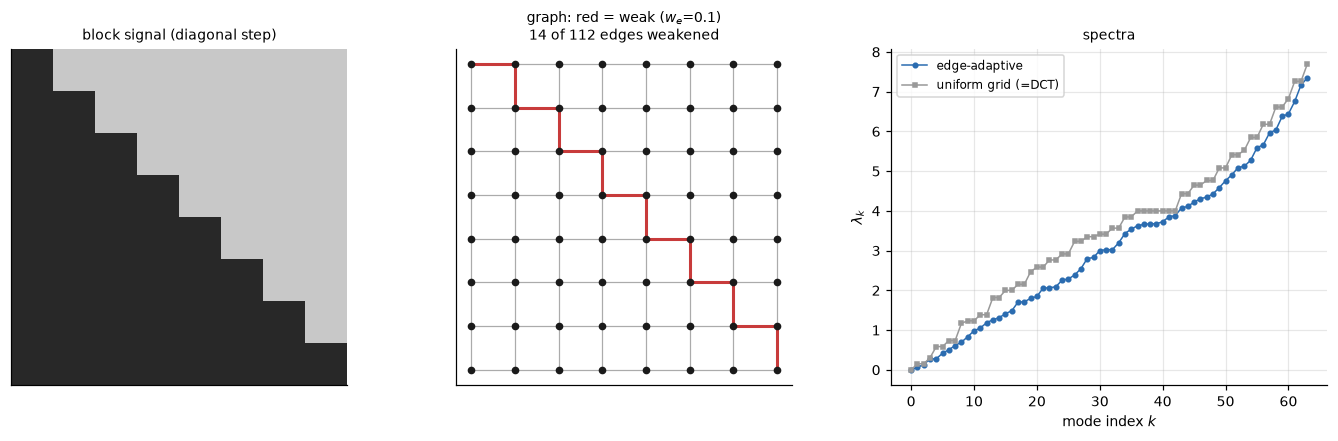

In [18]:
# --- a synthetic block with one diagonal step -------------------------------
yy, xx = np.mgrid[0:B, 0:B]
step_blk = np.where(yy > xx - 0.5, 40.0, 200.0)
T_EDGE, W_WEAK = 25, 0.1

mask = ic.weak_edge_mask(step_blk, edges, T_EDGE)
L_ea = ic.grid_laplacian(mask, edges, B * B, 1.0, W_WEAK)
lam_ea, U_ea = np.linalg.eigh(L_ea)
U_ea = ic.canonical_signs(U_ea[:, np.argsort(lam_ea)])
lam_ea = np.sort(lam_ea)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9))
axes[0].imshow(step_blk, **GRAY)
axes[0].set_title("block signal (diagonal step)", fontsize=9)
ys, xs = np.mgrid[0:B, 0:B]
for (i, j), m in zip(edges, mask):
    r1, c1 = divmod(i, B); r2, c2 = divmod(j, B)
    axes[1].plot([c1, c2], [r1, r2], color=(C_RED if m else "0.35"),
                 lw=(2.0 if m else 0.8), alpha=(0.95 if m else 0.5), zorder=1)
axes[1].scatter(xs.ravel(), ys.ravel(), s=16, c="0.1", zorder=3)
axes[1].invert_yaxis(); axes[1].set_aspect("equal")
axes[1].set_title(f"graph: red = weak ($w_e$={W_WEAK})\n"
                  f"{int(mask.sum())} of {len(edges)} edges weakened", fontsize=9)
axes[2].plot(lam_ea, "o-", ms=3, lw=1, color=C_LINE, label="edge-adaptive")
axes[2].plot(np.sort(lam_grid_an), "s-", ms=3, lw=1, color="0.6", label="uniform grid (=DCT)")
axes[2].set_xlabel("mode index $k$"); axes[2].set_ylabel(r"$\lambda_k$")
axes[2].set_title("spectra", fontsize=9); axes[2].legend(fontsize=8)
for ax in axes[:2]:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.show()

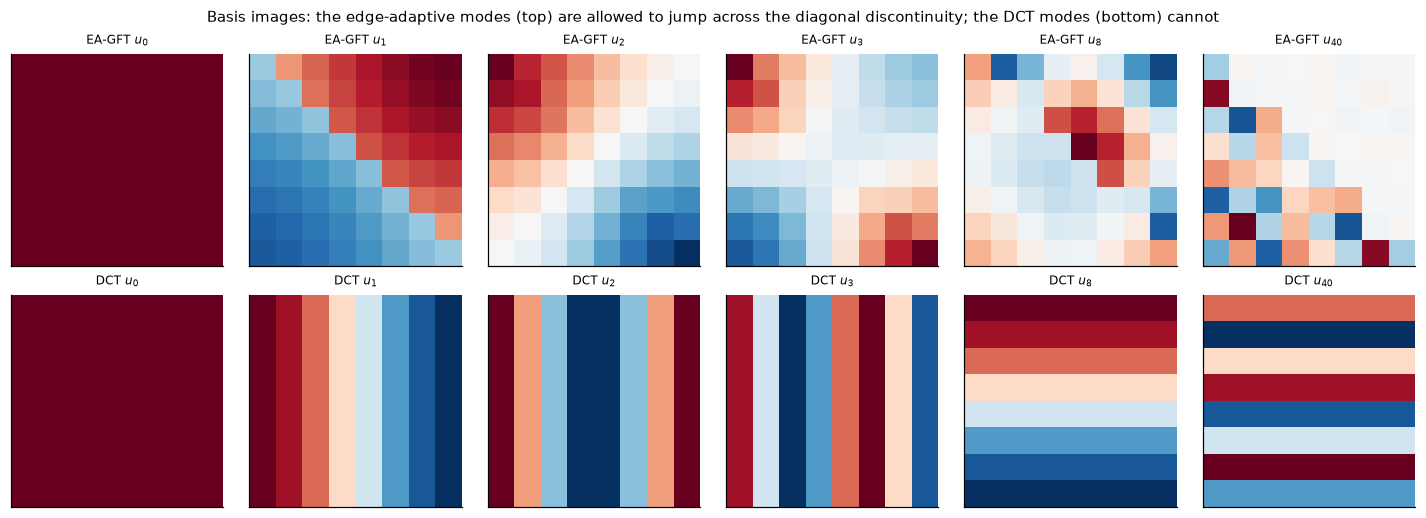

EA-GFT : energy in top 1 mode  95.0%, top 4  99.5%, top 8  99.8%   |  modes for 99% = 3
DCT    : energy in top 1 mode  32.9%, top 4  79.7%, top 8  87.4%   |  modes for 99% = 21

(the block MEAN is removed first, so this compares detail representation and a
 large DC term cannot flatter either basis)


In [19]:
fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for j, k in enumerate([0, 1, 2, 3, 8, 40]):
    for row, (Uu, nm) in enumerate([(U_ea, "EA-GFT"), (Phi, "DCT")]):
        v = Uu[:, k].reshape(B, B)
        m_ = np.abs(v).max()
        axes[row, j].imshow(v, cmap="RdBu_r", vmin=-m_, vmax=m_, interpolation="nearest")
        axes[row, j].set_title(f"{nm} $u_{{{k}}}$", fontsize=8)
        axes[row, j].set_xticks([]); axes[row, j].set_yticks([]); axes[row, j].grid(False)
fig.suptitle("Basis images: the edge-adaptive modes (top) are allowed to jump across the "
             "diagonal discontinuity; the DCT modes (bottom) cannot", fontsize=10)
plt.show()

x = step_blk.ravel() - step_blk.mean()
c_ea = U_ea.T @ x
c_dc = (Phi.T @ x)
for nm, c_ in [("EA-GFT", c_ea), ("DCT", c_dc)]:
    e = np.sort(c_ ** 2)[::-1]; tot = e.sum()
    print(f"{nm:7s}: energy in top 1 mode {e[0]/tot:6.1%}, top 4 {e[:4].sum()/tot:6.1%}, "
          f"top 8 {e[:8].sum()/tot:6.1%}   |  modes for 99% = "
          f"{int(np.searchsorted(np.cumsum(e)/tot, 0.99)+1)}")
print("\n(the block MEAN is removed first, so this compares detail representation and a")
print(" large DC term cannot flatter either basis)")

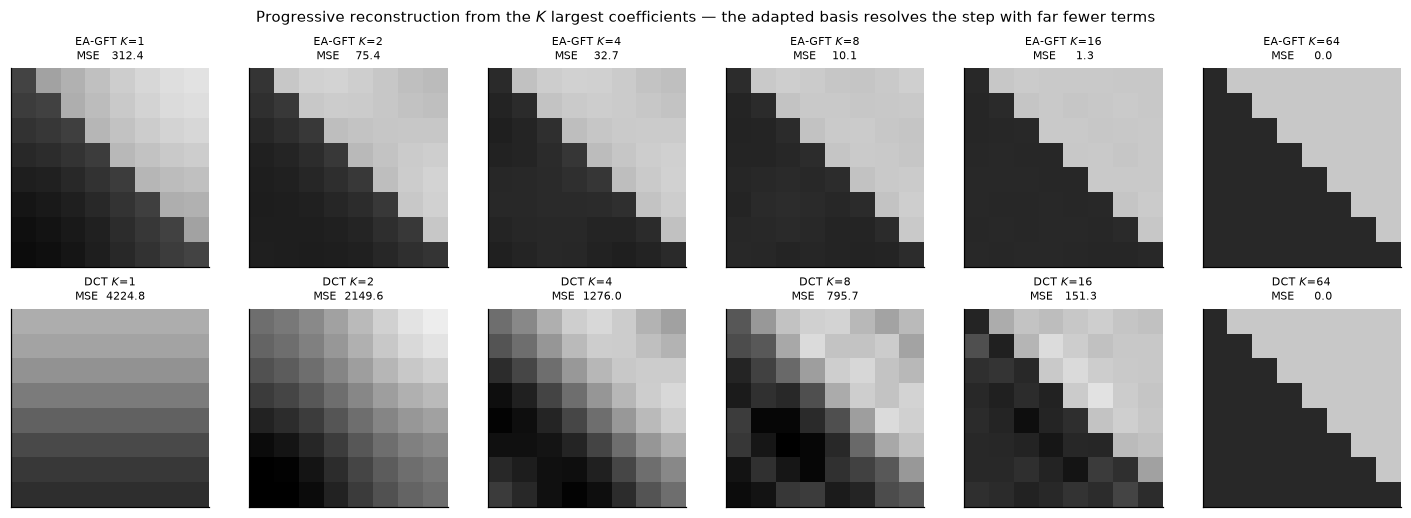

In [20]:
# --- progressive reconstruction of the step block ---------------------------
fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for row, (Uu, nm, cc) in enumerate([(U_ea, "EA-GFT", c_ea), (Phi, "DCT", c_dc)]):
    for j, K in enumerate([1, 2, 4, 8, 16, 64]):
        keep = np.zeros(64); idx = np.argsort(-np.abs(cc))[:K]; keep[idx] = cc[idx]
        r_ = (Uu @ keep).reshape(B, B) + step_blk.mean()
        axes[row, j].imshow(r_, **GRAY)
        axes[row, j].set_title(f"{nm} $K$={K}\nMSE {np.mean((r_-step_blk)**2):7.1f}", fontsize=7.5)
        axes[row, j].set_xticks([]); axes[row, j].set_yticks([]); axes[row, j].grid(False)
fig.suptitle("Progressive reconstruction from the $K$ largest coefficients — "
             "the adapted basis resolves the step with far fewer terms", fontsize=10)
plt.show()

---
## 7. Graph side information — the cost nobody mentions

Here is the problem in one sentence:

> **The decoder does not have the original block.** The mask was computed from original pixel
> differences, so the decoder cannot recompute it — it must be **transmitted**.

This is not a technicality; on natural images it dominates. Count it exactly.

A four-neighbour $8\times8$ grid has

$$2B(B-1) \;=\; 2\cdot 8\cdot 7 \;=\; 112$$

possible edges. One bit per edge is $112$ bits per block, and a block holds 64 pixels, so a literal
mask costs

$$\frac{112}{64} \;=\; 1.75 \ \text{bits per pixel}$$

**before a single coefficient is coded.** For comparison, the DCT codec reaches acceptable quality on
the camera image at well under 1 bpp *in total*. Side information alone would more than double it.

Two fixed weights ($w_c=1$, $w_e=0.1$) and the threshold $T$ are transmitted **once per image** in
the header, not per block, so they cost 9 bytes total and are negligible. What scales is the mask.


In [21]:
n_edges = 2 * B * (B - 1)
print(f"grid edges per block  2B(B-1) = 2*{B}*{B-1} = {n_edges}")
print(f"literal mask cost     = {n_edges} bits/block = {n_edges}/{B*B} = "
      f"{n_edges/(B*B):.2f} bits per pixel\n")
img_probe = demo_img[::2, ::2].astype(np.uint8)
Hp_, Wp_ = img_probe.shape
nblocks = (Hp_ // B) * (Wp_ // B)
print(f"for a {Hp_}x{Wp_} image: {nblocks} blocks")
print(f"  literal mask total  = {n_edges*nblocks/8:,.0f} bytes "
      f"({n_edges*nblocks/8/(Hp_*Wp_):.3f} of a byte per pixel)")
print(f"  raw pixel payload   = {Hp_*Wp_:,} bytes")
print(f"  -> the mask alone is {100*n_edges*nblocks/8/(Hp_*Wp_):.1f}% of the uncompressed image\n")

HS = struct.calcsize(ic._HDR)
print(f"{'image':10s}{'T':>4s}{'weak edges':>12s}{'mask raw B':>12s}{'zlib B':>9s}{'ratio':>8s}{'mask bpp':>10s}")
for nm, im_ in [("camera", img_probe), ("synthetic", SYNTH)]:
    for T_ in (15, 25, 40):
        by_raw = ic.encode(im_, method="gft", delta=16.0, threshold=T_, mask_mode=1)
        by_z   = ic.encode(im_, method="gft", delta=16.0, threshold=T_, mask_mode=2)
        mraw = struct.unpack(ic._HDR, by_raw[:HS])[11]
        mz   = struct.unpack(ic._HDR, by_z[:HS])[11]
        # count set bits for context
        ne = sum(int(ic.weak_edge_mask(b_ - b_.mean(), edges, T_).sum())
                 for b_ in ic.blockify(*ic.pad_to_blocks(im_.astype(float), B)[:1], B))
        h_, w_ = im_.shape
        print(f"{nm:10s}{T_:4d}{ne:12,d}{mraw:12,d}{mz:9,d}{mz/mraw:8.2f}"
              f"{8*mz/(h_*w_):10.3f}")
print("\nzlib on the packed mask bits is the 'simple lossless mask compression' baseline.")
print("It helps most when few edges are detected -- long runs of zeros compress well.")

grid edges per block  2B(B-1) = 2*8*7 = 112
literal mask cost     = 112 bits/block = 112/64 = 1.75 bits per pixel

for a 256x256 image: 1024 blocks
  literal mask total  = 14,336 bytes (0.219 of a byte per pixel)
  raw pixel payload   = 65,536 bytes
  -> the mask alone is 21.9% of the uncompressed image

image        T  weak edges  mask raw B   zlib B   ratio  mask bpp


camera      15      19,905      14,336    6,803    0.47     0.830


camera      25      11,262      14,336    5,089    0.35     0.621


camera      40       5,514      14,336    3,317    0.23     0.405


synthetic   15       1,084      14,336      680    0.05     0.083


synthetic   25       1,084      14,336      680    0.05     0.083


synthetic   40         938      14,336      585    0.04     0.071

zlib on the packed mask bits is the 'simple lossless mask compression' baseline.
It helps most when few edges are detected -- long runs of zeros compress well.


### Regenerating the basis identically at both ends

The decoder rebuilds $U$ from the mask alone, so three things must be pinned down or the two sides
produce different bases and the image is garbage:

1. **Vertex ordering** — raster within the block, fixed in `imcodec.block_edges`.
2. **Edge ordering** — all horizontal edges in raster order, then all vertical. The mask bits are
   written in exactly that order.
3. **Eigenvector signs** — `eigh` may return $-u_k$; we canonicalise so the entry of largest
   magnitude is positive (`imcodec.canonical_signs`).
4. **Repeated eigenvalues** — within a degenerate eigenspace the solver's rotation is arbitrary. The
   badly degenerate case is the *uniform* grid, so a block with **no** weak edges uses the analytic
   DCT basis instead of an eigensolver. That removes the only case where we saw ambiguity, and it is
   also what makes the Section 5 control exact.

Section 8 verifies this the only way that counts: decoding in a **fresh process** from the bytes.

> ⚠️ **A diagnostic is not a compression result.** It is tempting to report "the graph transform
> needs fewer coefficients", omitting the mask. That number is a legitimate *diagnostic of the
> transform*, and we show it — clearly labelled. It is **not** achievable compression, because a
> decoder handed only those coefficients cannot reconstruct anything.


In [22]:
# --- optional improvement: a small shared bank of graph templates -------------
# Instead of 112 bits per block, send an index into a fixed bank of masks.
blocks_probe = ic.blockify(ic.pad_to_blocks(img_probe.astype(float), B)[0], B)
masks_all = np.array([ic.weak_edge_mask(b_ - b_.mean(), edges, 25) for b_ in blocks_probe])
uniq, counts = np.unique(masks_all, axis=0, return_counts=True)
top = np.argsort(-counts)
print(f"distinct masks in this image: {len(uniq)} across {len(masks_all)} blocks")
print(f"the all-zero mask alone covers {counts[top[0]]/len(masks_all):6.1%} of blocks")
for n_tmpl in (16, 64, 256):
    cover = counts[top[:n_tmpl]].sum() / len(masks_all)
    idx_bits = int(np.ceil(np.log2(n_tmpl)))
    print(f"  bank of {n_tmpl:4d} templates: covers {cover:6.1%} of blocks exactly, "
          f"index costs {idx_bits} bits = {idx_bits/(B*B):.3f} bpp "
          f"(vs {n_edges/(B*B):.2f} bpp literal)")
print("\nThe adaptation-versus-signalling tradeoff in one table: a bank buys a ~20x cheaper")
print("signal at the price of using an approximate graph for the blocks it does not cover.")
print("We do not implement the bank codec here -- covering the remaining blocks needs an")
print("escape mechanism, and the honest comparison in Section 8 uses the literal mask.")

distinct masks in this image: 499 across 1024 blocks
the all-zero mask alone covers  50.9% of blocks
  bank of   16 templates: covers  52.8% of blocks exactly, index costs 4 bits = 0.062 bpp (vs 1.75 bpp literal)
  bank of   64 templates: covers  57.5% of blocks exactly, index costs 6 bits = 0.094 bpp (vs 1.75 bpp literal)
  bank of  256 templates: covers  76.3% of blocks exactly, index costs 8 bits = 0.125 bpp (vs 1.75 bpp literal)

The adaptation-versus-signalling tradeoff in one table: a bank buys a ~20x cheaper
signal at the price of using an approximate graph for the blocks it does not cover.
We do not implement the bank codec here -- covering the remaining blocks needs an
escape mechanism, and the honest comparison in Section 8 uses the literal mask.


---
## 8. A fair, decodable comparison

Three methods:

| Method | Purpose |
|---|---|
| **Teaching DCT codec** | transparent fixed-transform baseline |
| **Teaching EA-GFT codec** | measures graph adaptation *and its signalling cost* |
| **Real JPEG via Pillow** | a familiar practical reference |

**What is held identical** between the two teaching codecs, so that only the transform differs:
block size, the scalar quantizer, the entropy-coding implementation, the scan/symbol construction,
image preparation and padding. The controlled experiment uses **uniform** quantization,

$$q_i=\operatorname{round}(c_i/\Delta), \qquad \widetilde c_i = \Delta q_i,$$

with one $\Delta$ for every coefficient.

> ⚠️ **Why not use the JPEG table for both?** A JPEG quantization table assigns a step to each
> *spatial frequency* $(u,v)$, justified by how the eye responds to that frequency. A graph mode
> $u_k$ of a block-specific Laplacian has no such interpretation — it is not a fixed spatial
> frequency and its meaning changes from block to block. Applying the table to graph modes would be
> assigning perceptual weights to quantities they were never measured for. We therefore use uniform
> $\Delta$ for the controlled comparison and keep frequency-dependent quantization as a separate
> demonstration on the DCT, where it belongs.

### The container

Both teaching codecs write the same documented binary format, printed below. Everything the decoder
needs is in the bytes: dimensions, padding is implied by $H,W$ and $B$, quantizer settings, graph
parameters and mask, the Huffman tables, and explicit payload lengths.


In [23]:
print(ic.CONTAINER)
print(f"header size = {struct.calcsize(ic._HDR)} bytes")
print("\nThe Huffman tables are stored JPEG-DHT-style: 16 code-length counts followed by")
print("the symbols in canonical order, which is enough to rebuild the code uniquely.")


offset  type    field
0       4s      magic 'GTC1'
4       B       version (=1)
5       B       method  0 = DCT, 1 = EA-GFT
6       H       height  (true, before padding)
8       H       width
10      B       block size B
11      B       predictor 0 = none, 1 = causal DC prediction
12      f       quantizer step delta   (uniform) ; 0 => JPEG table mode
16      f       weak edge weight w_e   (GFT only, else 0)
20      B       edge threshold T       (GFT only, else 0)
21      B       mask mode 0 = none, 1 = raw bits, 2 = zlib(raw bits)
22      I       mask byte length
26      I       DC huffman table byte length
30      I       AC huffman table byte length
34      I       coefficient payload byte length
38      ...     mask bytes | DC table | AC table | payload

header size = 38 bytes

The Huffman tables are stored JPEG-DHT-style: 16 code-length counts followed by
the symbols in canonical order, which is enough to rebuild the code uniquely.


In [24]:
# ============ THE DECISIVE CHECK: decode(encode(image, settings)) ============
probe = CAMERA
results_rt = []
for meth in ("dct", "gft"):
    for pred in (0, 1):
        by = ic.encode(probe, method=meth, delta=16.0, predictor=pred, threshold=25)
        rec = ic.decode(by)
        results_rt.append((meth, pred, len(by), ic.psnr(probe, rec), rec.shape == probe.shape))
print(f"{'method':7s}{'pred':>5s}{'bytes':>9s}{'PSNR dB':>10s}{'shape ok':>10s}")
for m_, p_, n_, ps_, ok_ in results_rt:
    print(f"{m_:7s}{p_:5d}{n_:9d}{ps_:10.2f}{str(ok_):>10s}")

# non-multiple-of-8 dimensions must round-trip too
odd = probe[:250, :237]
for meth in ("dct", "gft"):
    by = ic.encode(odd, method=meth, delta=16.0)
    rec = ic.decode(by)
    print(f"\nodd size {odd.shape} via {meth}: decoded {rec.shape}, "
          f"PSNR {ic.psnr(odd, rec):.2f} dB")

method  pred    bytes   PSNR dB  shape ok
dct        0    11608     37.19      True
dct        1    11606     37.18      True
gft        0    13993     36.94      True
gft        1    13991     36.47      True



odd size (250, 237) via dct: decoded (250, 237), PSNR 37.22 dB



odd size (250, 237) via gft: decoded (250, 237), PSNR 37.03 dB


In [25]:
# Write real files, then decode them in a SEPARATE PYTHON PROCESS that gets
# nothing but the bytes -- no encoder objects, no coefficient arrays, no originals.
paths = {}
for meth in ("dct", "gft"):
    by = ic.encode(CAMERA, method=meth, delta=16.0, threshold=25)
    p_ = os.path.join(OUT_DIR, f"camera_{meth}_d16.gtc")
    with open(p_, "wb") as fh:
        fh.write(by)
    paths[meth] = p_
    print(f"wrote {p_}  ({len(by):,} bytes)")

# Python puts the SCRIPT's directory on sys.path, not the working directory, so the
# helper has to be told where imcodec lives. Everything else it receives is bytes.
script = (
    "import sys, os, numpy as np\n"
    "sys.path.insert(0, sys.argv[1])\n"
    "import imcodec as ic\n"
    "for p in sys.argv[2:]:\n"
    "    data = open(p, 'rb').read()\n"
    "    img = ic.decode(data)\n"
    "    np.save(p + '.npy', img)\n"
    "    print(f'  {os.path.basename(p)}: {len(data)} bytes in -> {img.shape} {img.dtype} "
    "out, mean {img.mean():.3f}')\n")
sp = os.path.join(OUT_DIR, "_fresh_decode.py")
with open(sp, "w") as fh:
    fh.write(script)

print("\n--- fresh process ---")
res = subprocess.run([sys.executable, sp, os.getcwd(), *paths.values()],
                     capture_output=True, text=True, cwd=os.getcwd())
print(res.stdout.rstrip() or res.stderr[-600:])
for meth, p_ in paths.items():
    fresh = np.load(p_ + ".npy")
    same = np.array_equal(fresh, ic.decode(open(p_, "rb").read()))
    print(f"{meth}: fresh-process output identical to in-notebook decode: {same}; "
          f"PSNR {ic.psnr(CAMERA, fresh):.2f} dB")

wrote out\camera_dct_d16.gtc  (11,608 bytes)


wrote out\camera_gft_d16.gtc  (13,993 bytes)

--- fresh process ---


  camera_dct_d16.gtc: 11608 bytes in -> (256, 256) uint8 out, mean 129.051
  camera_gft_d16.gtc: 13993 bytes in -> (256, 256) uint8 out, mean 129.051
dct: fresh-process output identical to in-notebook decode: True; PSNR 37.19 dB


gft: fresh-process output identical to in-notebook decode: True; PSNR 36.94 dB


### Real JPEG, for reference

Pillow writes a complete JPEG file: markers, headers, its own Huffman tables, and a quantization
table scaled by the `quality` parameter. We measure the **whole file**, because that is what you
would store.

> ⚠️ **`quality` is not a compression ratio and not $\Delta$.** It is an index into a table-scaling
> rule; the relationship to rate and to distortion is image-dependent and non-linear. The only
> defensible way to compare is to plot both against **measured bitrate**, which is what Section 10
> does. See [Pillow's JPEG options](https://pillow.readthedocs.io/en/stable/handbook/image-file-formats.html#jpeg).


In [26]:
def jpeg_roundtrip(img, quality, subsampling=0, optimize=True):
    """Write a real grayscale JPEG file and read it back. Returns (bytes, reconstruction)."""
    buf = io.BytesIO()
    Image.fromarray(img).save(buf, format="JPEG", quality=int(quality),
                              optimize=optimize, subsampling=subsampling)
    by = buf.getvalue()
    rec = np.array(Image.open(io.BytesIO(by)).convert("L"))
    return by, rec

H_, W_ = CAMERA.shape
print(f"{'quality':>8s}{'bytes':>9s}{'bpp':>8s}{'PSNR dB':>10s}   (real JPEG, grayscale, optimize=True)")
for q_ in (10, 25, 50, 75, 90, 95):
    by, rec = jpeg_roundtrip(CAMERA, q_)
    print(f"{q_:8d}{len(by):9,d}{ic.bpp(len(by),H_,W_):8.3f}{ic.psnr(CAMERA,rec):10.2f}")
p_ = os.path.join(OUT_DIR, "camera_jpeg_q50.jpg")
with open(p_, "wb") as fh:
    fh.write(jpeg_roundtrip(CAMERA, 50)[0])
print(f"\nsaved a representative file: {p_}")

 quality    bytes     bpp   PSNR dB   (real JPEG, grayscale, optimize=True)
      10    2,031   0.248     26.14
      25    4,246   0.518     28.39
      50    6,968   0.851     30.38
      75   10,945   1.336     33.18
      90   18,295   2.233     39.25
      95   25,020   3.054     44.28

saved a representative file: out\camera_jpeg_q50.jpg


---
## 9-10. Experiments and measured bitrates

### The images

Three images with deliberately different statistics, all $256\times256$ 8-bit grayscale, identical
arrays across every method:

| Image | Character | Provenance |
|---|---|---|
| **camera** | smooth regions plus prominent boundaries | `skimage.data.camera()`, downsampled 2x |
| **grass** | texture-rich, little smooth area | `skimage.data.grass()`, top-left 256x256 crop |
| **synthetic** | piecewise smooth, diagonal and curved boundaries | generated here, seed fixed |

> 📖 Provenance and licensing: [scikit-image dataset documentation](https://scikit-image.org/docs/stable/api/skimage.data.html).
> `camera()` is a public-domain standard test image redistributed by scikit-image; `grass()` is from
> scikit-image's own data collection (CC0). Both are bundled with the installed package, so no
> download occurs at run time. The exact cropping and downsampling are in the cell below — no other
> preprocessing is applied.

### How we measure

$$\mathrm{bpp}=\frac{8\,\text{file bytes}}{HW},\qquad
\text{ratio}=\frac{\text{raw pixel bytes}}{\text{file bytes}},\qquad
\text{reduction}=100\left(1-\frac{\text{file bytes}}{\text{raw pixel bytes}}\right)\%$$

$$\mathrm{MSE}=\frac1{HW}\sum_{i,j}(X_{ij}-\widehat X_{ij})^2, \qquad
\mathrm{PSNR}=10\log_{10}\frac{255^2}{\mathrm{MSE}} \ \text{dB}$$

The denominator is always **raw pixel storage** ($HW$ bytes), never the size of a PNG of the same
image. PSNR is reported as $\infty$ when the reconstruction is exact.

> ⚠️ **Keeping $K$ coefficients is not a $64/K$ compression ratio.** Their *positions* and *values*
> also have to be transmitted. Every number in the table below is the size of a real file.


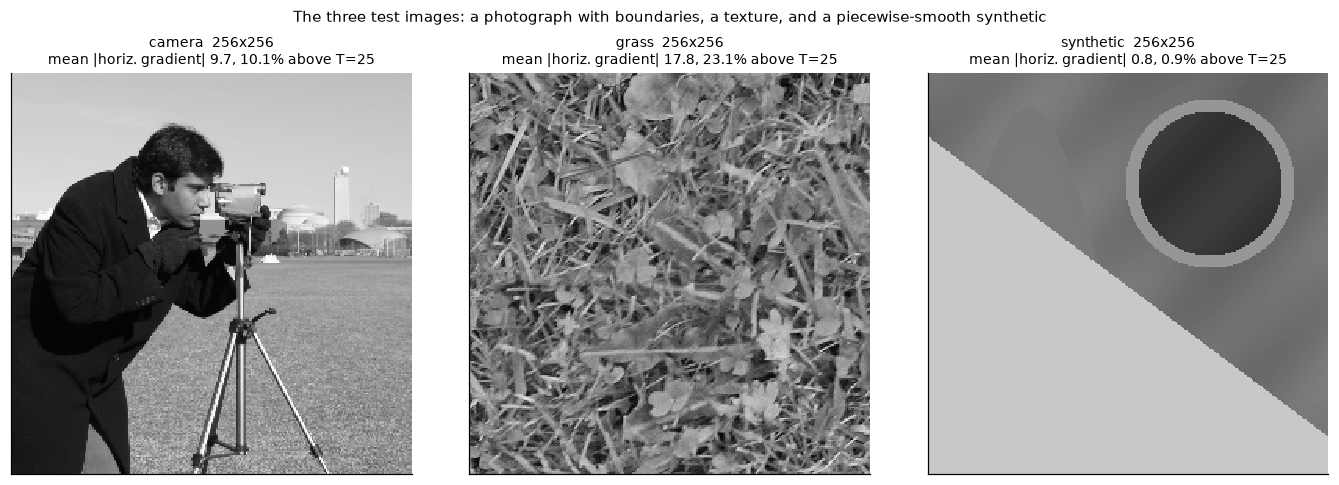

camera     sha1=c15500962f5a  raw 65,536 bytes  range 1..255
grass      sha1=9b77a8ce4233  raw 65,536 bytes  range 3..232
synthetic  sha1=f47e4e82ccee  raw 65,536 bytes  range 49..200


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.3))
for ax, (nm, im_) in zip(axes, IMAGES.items()):
    ax.imshow(im_, **GRAY)
    g = np.abs(np.diff(im_.astype(float), axis=1))
    ax.set_title(f"{nm}  {im_.shape[0]}x{im_.shape[1]}\n"
                 f"mean |horiz. gradient| {g.mean():.1f}, "
                 f"{100*(g>25).mean():.1f}% above T=25", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("The three test images: a photograph with boundaries, a texture, and a "
             "piecewise-smooth synthetic", fontsize=10)
plt.show()
for nm, im_ in IMAGES.items():
    print(f"{nm:10s} sha1={hashlib.sha1(im_.tobytes()).hexdigest()[:12]}  "
          f"raw {im_.nbytes:,} bytes  range {im_.min()}..{im_.max()}")

In [28]:
# ============================ THE SWEEP =====================================
DELTAS = [4, 8, 12, 16, 24, 32, 48, 64, 96, 128]
QUALITIES = [5, 10, 15, 20, 30, 40, 50, 60, 75, 85, 92, 96]
HS = struct.calcsize(ic._HDR)
rows = []
t0 = time.time()
for nm, im_ in IMAGES.items():
    H_, W_ = im_.shape
    raw = im_.nbytes
    for d in DELTAS:
        for meth in ("dct", "gft"):
            by = ic.encode(im_, method=meth, delta=float(d), threshold=25, w_weak=0.1)
            rec = ic.decode(by)
            f = struct.unpack(ic._HDR, by[:HS])
            mask_b, dct_b, act_b, pay_b = f[11], f[12], f[13], f[14]
            rows.append(dict(image=nm, method={"dct": "DCT", "gft": "EA-GFT"}[meth],
                             setting=f"delta={d}", bytes=len(by), payload=pay_b,
                             side=mask_b + dct_b + act_b + HS,
                             mask_bytes=mask_b,
                             bpp=ic.bpp(len(by), H_, W_),
                             ratio=raw / len(by),
                             reduction=100 * (1 - len(by) / raw),
                             mse=ic.mse(im_, rec), psnr=ic.psnr(im_, rec)))
    for q_ in QUALITIES:
        by, rec = jpeg_roundtrip(im_, q_)
        rows.append(dict(image=nm, method="JPEG (Pillow)", setting=f"quality={q_}",
                         bytes=len(by), payload=np.nan, side=np.nan, mask_bytes=0,
                         bpp=ic.bpp(len(by), H_, W_), ratio=raw / len(by),
                         reduction=100 * (1 - len(by) / raw),
                         mse=ic.mse(im_, rec), psnr=ic.psnr(im_, rec)))
import pandas as pd
R = pd.DataFrame(rows)
R.to_csv(os.path.join(OUT_DIR, "lesson5_results.csv"), index=False)
print(f"{len(R)} encodes in {time.time()-t0:.1f}s -> {OUT_DIR}/lesson5_results.csv")
print(R.groupby(["image", "method"]).agg(
    n=("bytes", "size"), bpp_lo=("bpp", "min"), bpp_hi=("bpp", "max"),
    psnr_lo=("psnr", "min"), psnr_hi=("psnr", "max")).to_string(float_format=lambda v: f"{v:.2f}"))

96 encodes in 106.5s -> out/lesson5_results.csv
                          n  bpp_lo  bpp_hi  psnr_lo  psnr_hi
image     method                                             
camera    DCT            10    0.17    2.87    25.14    47.56
          EA-GFT         10    0.76    3.14    26.80    43.28
          JPEG (Pillow)  12    0.14    3.33    24.37    45.96
grass     DCT            10    0.32    4.08    21.52    48.38
          EA-GFT         10    1.65    5.53    23.48    41.46
          JPEG (Pillow)  12    0.27    4.62    21.08    45.92
synthetic DCT            10    0.07    0.72    29.09    53.82
          EA-GFT         10    0.14    0.43    31.09    50.23
          JPEG (Pillow)  12    0.08    0.95    28.76    53.03


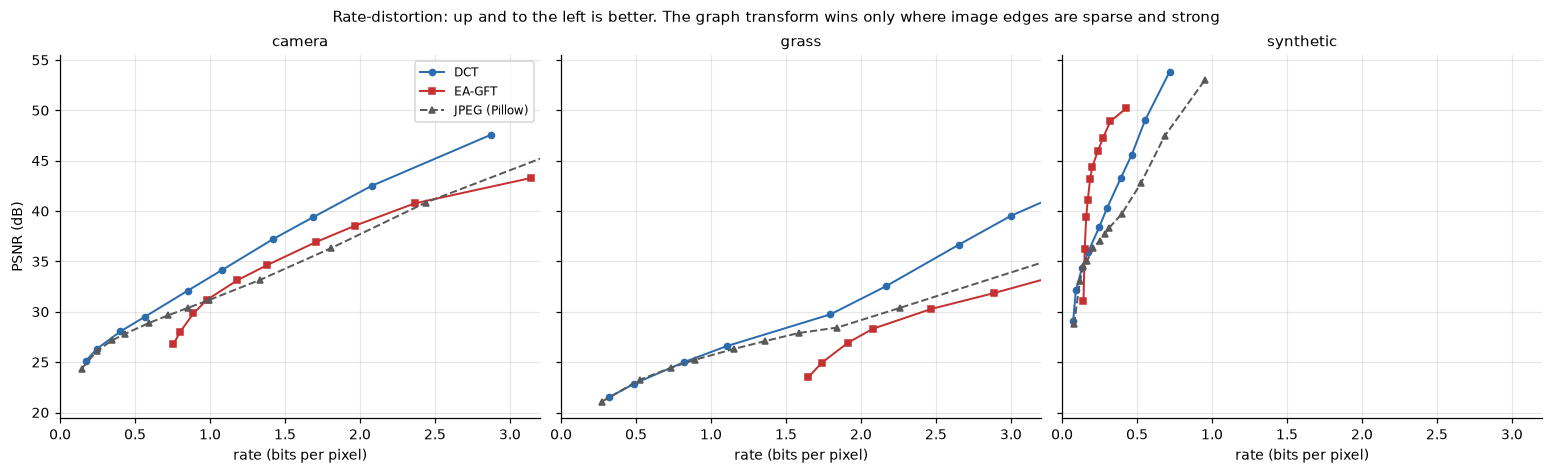

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
style = {"DCT": (C_LINE, "o-"), "EA-GFT": (C_RED, "s-"), "JPEG (Pillow)": ("0.35", "^--")}
for ax, nm in zip(axes, IMAGES):
    for meth, (col, mk) in style.items():
        sub = R[(R.image == nm) & (R.method == meth)].sort_values("bpp")
        ax.plot(sub.bpp, sub.psnr, mk, color=col, ms=4, lw=1.3, label=meth)
    ax.set_xlabel("rate (bits per pixel)"); ax.set_title(nm, fontsize=10)
    ax.set_xlim(0, 3.2)
axes[0].set_ylabel("PSNR (dB)"); axes[0].legend(fontsize=8)
fig.suptitle("Rate-distortion: up and to the left is better. The graph transform wins only "
             "where image edges are sparse and strong", fontsize=10)
plt.show()

In [30]:
# Matched-rate comparison: for each image, pick the operating point of each method
# closest to a target bitrate and report the ACTUAL rate achieved.
def at_rate(df, image, method, target):
    sub = df[(df.image == image) & (df.method == method)]
    return sub.iloc[(sub.bpp - target).abs().argmin()]

print(f"{'image':10s}{'target':>7s}{'method':>15s}{'setting':>14s}"
      f"{'actual bpp':>12s}{'PSNR dB':>9s}{'ratio':>7s}{'mask %':>8s}")
for nm in IMAGES:
    for tgt in (0.5, 1.0):
        for meth in ("DCT", "EA-GFT", "JPEG (Pillow)"):
            r_ = at_rate(R, nm, meth, tgt)
            mk = "" if not np.isfinite(r_.side) else f"{100*r_.mask_bytes/r_.bytes:7.1f}"
            print(f"{nm:10s}{tgt:7.2f}{meth:>15s}{r_.setting:>14s}"
                  f"{r_.bpp:12.3f}{r_.psnr:9.2f}{r_.ratio:7.2f}{mk:>8s}")
    print()
print("Exact rate matching is impossible with discrete settings, so the ACTUAL rate is")
print("shown for every row and the comparison is read against it, not against the target.")

image      target         method       setting  actual bpp  PSNR dB  ratio  mask %
camera       0.50            DCT      delta=48       0.567    29.52  14.10     0.0
camera       0.50         EA-GFT     delta=128       0.756    26.80  10.58    82.1
camera       0.50  JPEG (Pillow)    quality=20       0.436    27.83  18.36        
camera       1.00            DCT      delta=24       1.082    34.16   7.40     0.0
camera       1.00         EA-GFT      delta=48       0.979    31.19   8.17    63.5
camera       1.00  JPEG (Pillow)    quality=60       0.992    31.16   8.07        

grass        0.50            DCT      delta=96       0.488    22.86  16.40     0.0
grass        0.50         EA-GFT     delta=128       1.649    23.48   4.85    83.5
grass        0.50  JPEG (Pillow)    quality=10       0.529    23.27  15.13        
grass        1.00            DCT      delta=48       1.109    26.61   7.22     0.0
grass        1.00         EA-GFT     delta=128       1.649    23.48   4.85    83.5
gra

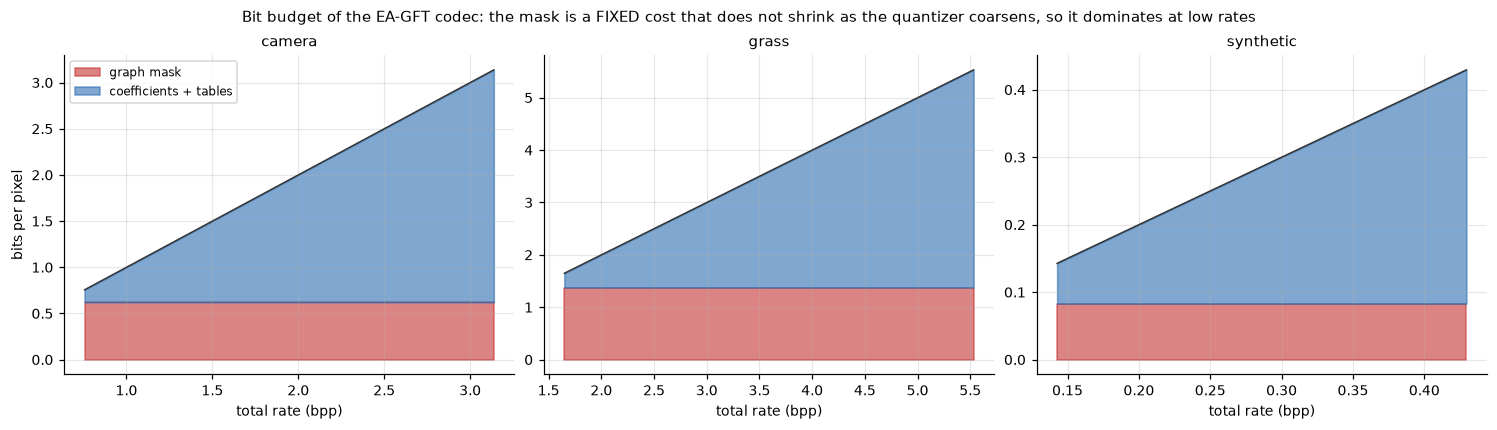

camera    : mask is  82.1% of the stream at 0.76 bpp, and  19.8% at 3.14 bpp
grass     : mask is  83.5% of the stream at 1.65 bpp, and  24.9% at 5.53 bpp
synthetic : mask is  58.2% of the stream at 0.14 bpp, and  19.3% at 0.43 bpp


In [31]:
# Where do the bits go in the EA-GFT stream?
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
for ax, nm in zip(axes, IMAGES):
    sub = R[(R.image == nm) & (R.method == "EA-GFT")].sort_values("bpp")
    H_, W_ = IMAGES[nm].shape
    ax.fill_between(sub.bpp, 0, 8 * sub.mask_bytes / (H_ * W_), color=C_RED, alpha=0.6,
                    label="graph mask")
    ax.fill_between(sub.bpp, 8 * sub.mask_bytes / (H_ * W_), sub.bpp, color=C_LINE, alpha=0.6,
                    label="coefficients + tables")
    ax.plot(sub.bpp, sub.bpp, color="0.2", lw=1)
    ax.set_xlabel("total rate (bpp)"); ax.set_title(nm, fontsize=10)
axes[0].set_ylabel("bits per pixel"); axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Bit budget of the EA-GFT codec: the mask is a FIXED cost that does not shrink "
             "as the quantizer coarsens, so it dominates at low rates", fontsize=10)
plt.show()

for nm in IMAGES:
    sub = R[(R.image == nm) & (R.method == "EA-GFT")]
    lo, hi = sub.loc[sub.bpp.idxmin()], sub.loc[sub.bpp.idxmax()]
    print(f"{nm:10s}: mask is {100*lo.mask_bytes/lo.bytes:5.1f}% of the stream at "
          f"{lo.bpp:.2f} bpp, and {100*hi.mask_bytes/hi.bytes:5.1f}% at {hi.bpp:.2f} bpp")

In [32]:
# The prediction experiment, both teaching transforms, one quantizer step.
pred_rows = []
for nm, im_ in IMAGES.items():
    H_, W_ = im_.shape
    for meth in ("dct", "gft"):
        for pred in (0, 1):
            for d in (16.0, 48.0):
                by = ic.encode(im_, method=meth, delta=d, predictor=pred, threshold=25)
                rec = ic.decode(by)
                pred_rows.append(dict(image=nm, method={"dct":"DCT","gft":"EA-GFT"}[meth],
                                      predictor=["none","causal DC"][pred], delta=d,
                                      bpp=ic.bpp(len(by), H_, W_), psnr=ic.psnr(im_, rec)))
P = pd.DataFrame(pred_rows)
piv = P.pivot_table(index=["image","method","delta"], columns="predictor",
                    values=["bpp","psnr"])
print(piv.to_string(float_format=lambda v: f"{v:.3f}"))
print("\nThe causal DC predictor changes the rate by well under a percent. That is the")
print("measured version of Section 4's argument: a block-constant prediction is almost")
print("exactly what differential DC coding already removes, so it has little left to do.")

                             bpp            psnr       
predictor              causal DC  none causal DC   none
image     method delta                                 
camera    DCT    16.0      1.417 1.417    37.175 37.186
                 48.0      0.567 0.567    29.535 29.523
          EA-GFT 16.0      1.708 1.708    36.467 36.937
                 48.0      0.979 0.979    31.066 31.187
grass     DCT    16.0      2.656 2.653    36.658 36.662
                 48.0      1.114 1.109    26.612 26.610
          EA-GFT 16.0      3.522 3.518    33.107 34.450
                 48.0      2.085 2.080    28.053 28.318
synthetic DCT    16.0      0.384 0.392    43.255 43.315
                 48.0      0.171 0.173    35.552 35.923
          EA-GFT 16.0      0.229 0.239    45.333 45.982
                 48.0      0.168 0.171    40.735 41.108

The causal DC predictor changes the rate by well under a percent. That is the
measured version of Section 4's argument: a block-constant prediction is almost
e

---
## 11. Looking at the reconstructions

Numbers decide the comparison, but they do not show *what* was lost. Everything below uses fixed
grayscale limits $[0,255]$ and nearest-neighbour rendering so that no display interpolation hides
pixel-level damage.


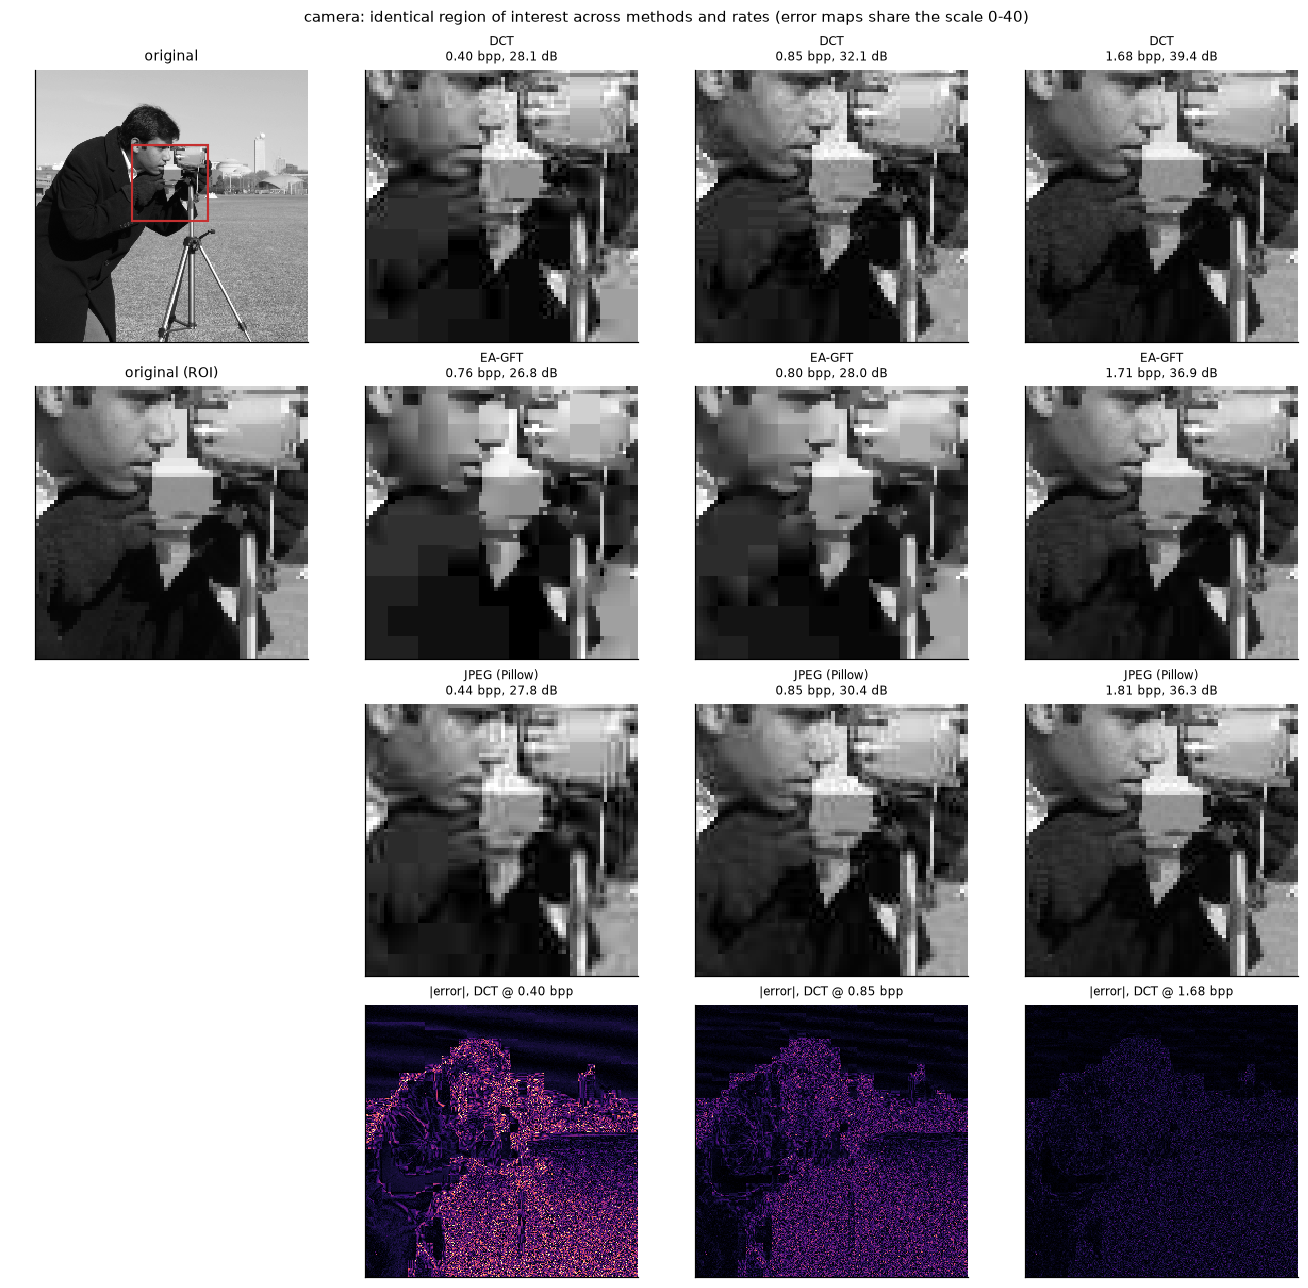

In [33]:
ROI = dict(camera=(70, 90, 72, 72), grass=(60, 60, 72, 72), synthetic=(40, 120, 72, 72))

def panel(nm, targets=(0.4, 0.8, 1.6)):
    im_ = IMAGES[nm]; H_, W_ = im_.shape
    r0, c0, hh, ww = ROI[nm]
    methods = ["DCT", "EA-GFT", "JPEG (Pillow)"]
    fig, axes = plt.subplots(len(methods) + 1, len(targets) + 1,
                             figsize=(3.0 * (len(targets) + 1), 2.9 * (len(methods) + 1)))
    axes[0, 0].imshow(im_, **GRAY); axes[0, 0].set_title("original", fontsize=9)
    axes[0, 0].add_patch(Rectangle((c0, r0), ww, hh, ec=C_RED, fc="none", lw=1.4))
    axes[1, 0].imshow(im_[r0:r0+hh, c0:c0+ww], **GRAY)
    axes[1, 0].set_title("original (ROI)", fontsize=9)
    for k in (2, 3):
        axes[k, 0].axis("off")
    for j, tgt in enumerate(targets, start=1):
        for i, meth in enumerate(methods):
            r_ = at_rate(R, nm, meth, tgt)
            if meth == "JPEG (Pillow)":
                _, rec = jpeg_roundtrip(im_, int(r_.setting.split("=")[1]))
            else:
                by = ic.encode(im_, method={"DCT":"dct","EA-GFT":"gft"}[meth],
                               delta=float(r_.setting.split("=")[1]), threshold=25)
                rec = ic.decode(by)
            axes[i, j].imshow(rec[r0:r0+hh, c0:c0+ww], **GRAY)
            axes[i, j].set_title(f"{meth}\n{r_.bpp:.2f} bpp, {r_.psnr:.1f} dB", fontsize=8)
            if i == 0:
                axes[3, j].imshow(np.abs(im_.astype(float) - rec.astype(float)),
                                  cmap="magma", vmin=0, vmax=40, interpolation="nearest")
                axes[3, j].set_title(f"|error|, DCT @ {r_.bpp:.2f} bpp", fontsize=8)
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    fig.suptitle(f"{nm}: identical region of interest across methods and rates "
                 f"(error maps share the scale 0-40)", fontsize=10)
    plt.show()

panel("camera")

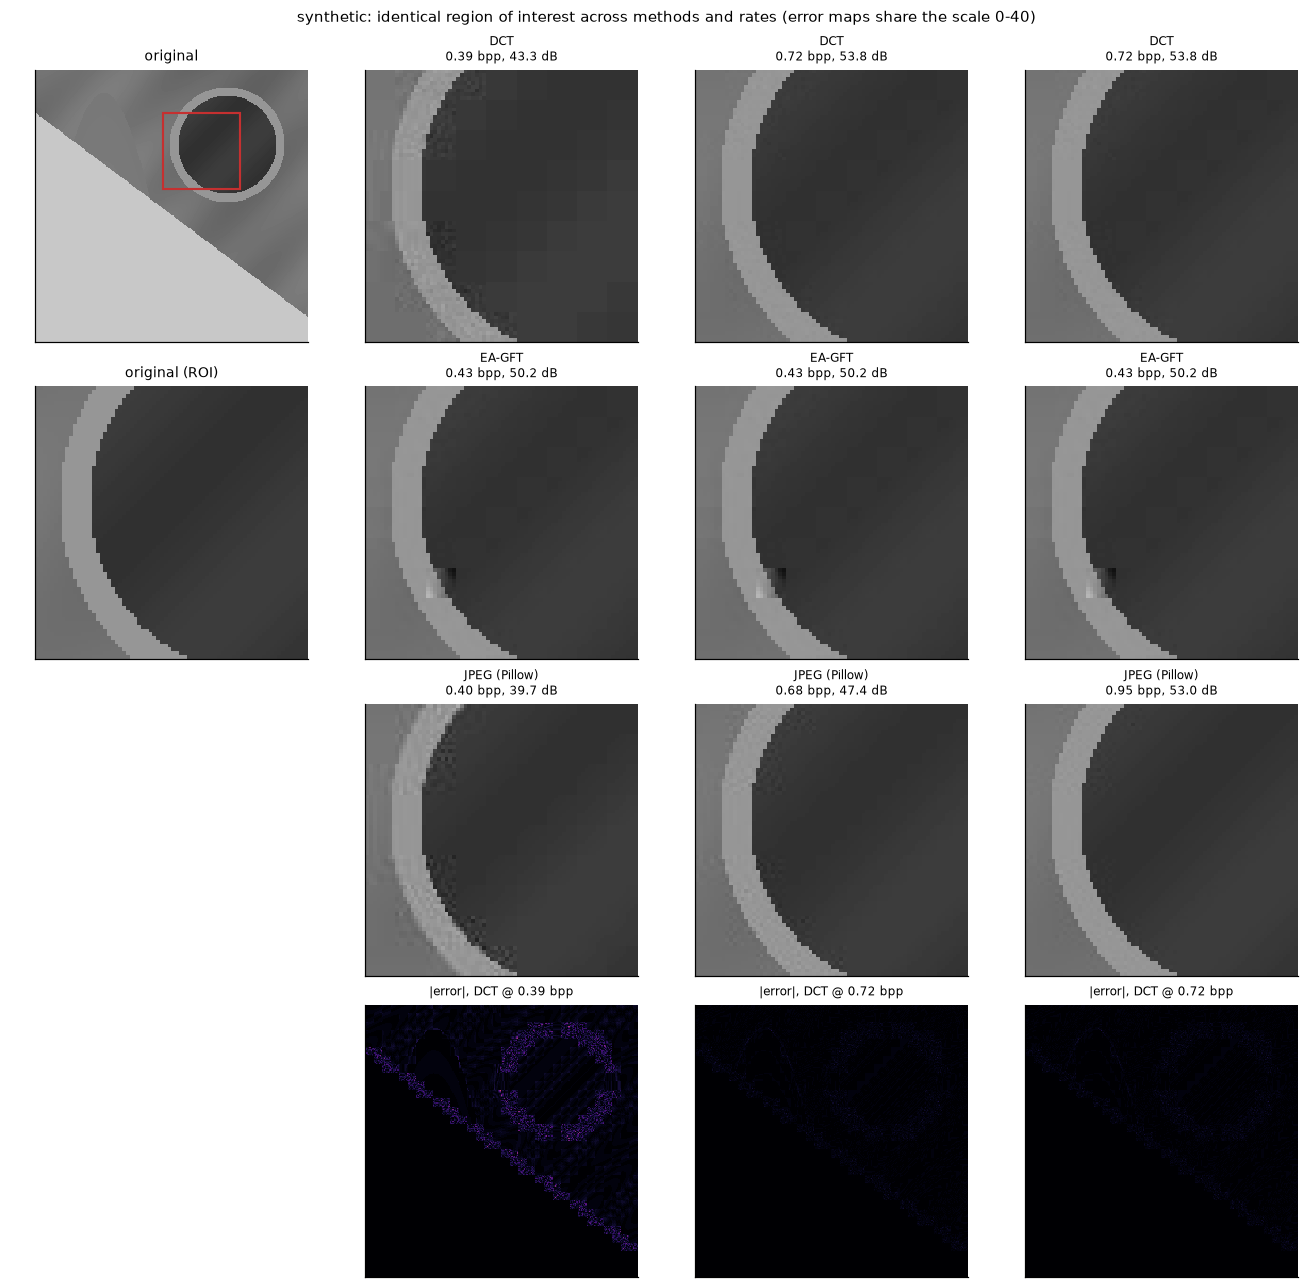

In [34]:
panel("synthetic")

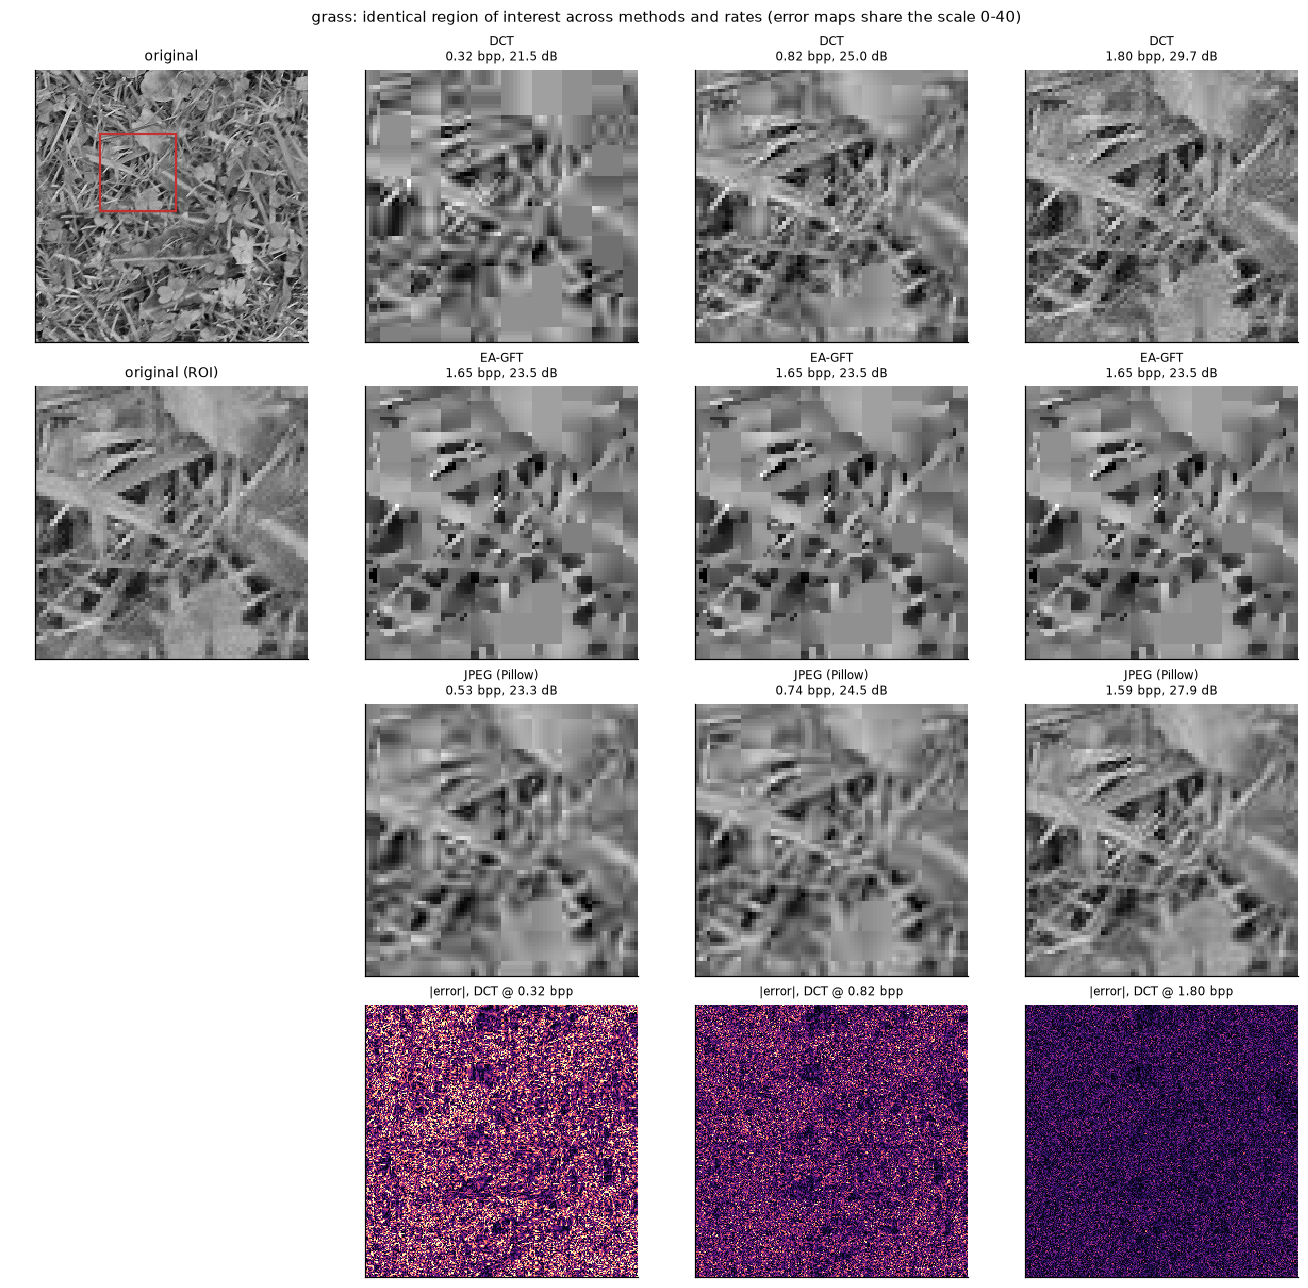

In [35]:
panel("grass")


original (block at row 96, col 120):
      38   145   143   145   145   147   145   146
      36   143   146   147   146   147   142   145
      70   145   146   147   147   147   146   145
     129   143   146   145   145   147   146   146
     146   147   145   147   144   144   146   145
     143   144   145   145   145   145   146   146
     119   138   144   143   145   144   147   148
      70    73   145   143   145   140   135   124

reconstruction (block at row 96, col 120):
      16   146   159   150   164   149   160   169
      27   141   153   148   166   150   148   147
      57   141   148   145   166   154   139   129
     107   151   147   139   161   161   144   135
     149   158   150   136   153   166   154   155
     154   146   150   138   146   163   153   163
     122   114   147   145   143   153   135   148
      87    87   143   151   143   144   117   128

error (block at row 96, col 120):
      22    -1   -16    -5   -19    -2   -15   -23
       9     2  

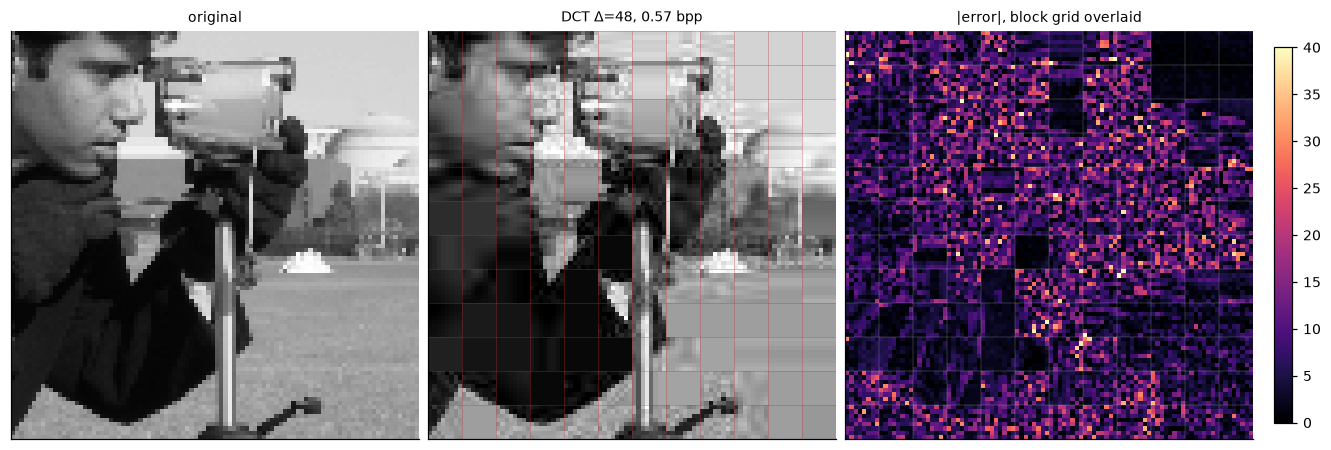


What to look for: blur where fine texture has been quantized away, ringing
(over/undershoot) beside strong edges, and error that changes abruptly at the
8-pixel block boundaries -- the signature of independent per-block quantization.


In [36]:
# One numerical 8x8 comparison, with the block grid drawn on the reconstruction.
nm = "camera"; im_ = IMAGES[nm]
by = ic.encode(im_, method="dct", delta=48.0)
rec = ic.decode(by)
r0, c0 = 96, 120
o_ = im_[r0:r0+B, c0:c0+B].astype(int)
r_ = rec[r0:r0+B, c0:c0+B].astype(int)
for nm_, A in [("original", o_), ("reconstruction", r_), ("error", o_ - r_)]:
    print(f"\n{nm_} (block at row {r0}, col {c0}):")
    for row in A:
        print("   " + " ".join(f"{v:5d}" for v in row))
print(f"\nblock MSE {np.mean((o_-r_).astype(float)**2):.2f}, "
      f"max |error| {np.abs(o_-r_).max()}, image PSNR {ic.psnr(im_, rec):.2f} dB "
      f"at {ic.bpp(len(by), *im_.shape):.3f} bpp")

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
axes[0].imshow(im_[64:160, 96:192], **GRAY); axes[0].set_title("original", fontsize=9)
axes[1].imshow(rec[64:160, 96:192], **GRAY)
axes[1].set_title(f"DCT $\\Delta$=48, {ic.bpp(len(by), *im_.shape):.2f} bpp", fontsize=9)
for g in range(0, 96, B):
    axes[1].axhline(g - 0.5, color=C_RED, lw=0.35, alpha=0.6)
    axes[1].axvline(g - 0.5, color=C_RED, lw=0.35, alpha=0.6)
e = axes[2].imshow(np.abs(im_[64:160, 96:192].astype(float) - rec[64:160, 96:192].astype(float)),
                   cmap="magma", vmin=0, vmax=40, interpolation="nearest")
axes[2].set_title("|error|, block grid overlaid", fontsize=9)
for g in range(0, 96, B):
    axes[2].axhline(g - 0.5, color="w", lw=0.3, alpha=0.4)
    axes[2].axvline(g - 0.5, color="w", lw=0.3, alpha=0.4)
fig.colorbar(e, ax=axes[2], fraction=0.046)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.show()
print("\nWhat to look for: blur where fine texture has been quantized away, ringing")
print("(over/undershoot) beside strong edges, and error that changes abruptly at the")
print("8-pixel block boundaries -- the signature of independent per-block quantization.")

In [37]:
# Optional interactive controls; static outputs above stand on their own.
try:
    import ipywidgets as W
    from IPython.display import display

    def explore(image="camera", delta=32, threshold=25, method="EA-GFT"):
        im_ = IMAGES[image]
        by = ic.encode(im_, method={"DCT": "dct", "EA-GFT": "gft"}[method],
                       delta=float(delta), threshold=int(threshold))
        rec = ic.decode(by)
        fig, ax = plt.subplots(1, 3, figsize=(12, 4))
        ax[0].imshow(im_, **GRAY); ax[0].set_title("original", fontsize=9)
        ax[1].imshow(rec, **GRAY)
        ax[1].set_title(f"{method}  {ic.bpp(len(by), *im_.shape):.3f} bpp  "
                        f"{ic.psnr(im_, rec):.2f} dB", fontsize=9)
        d_ = ax[2].imshow(np.abs(im_.astype(float) - rec.astype(float)),
                          cmap="magma", vmin=0, vmax=40, interpolation="nearest")
        ax[2].set_title("|error|", fontsize=9)
        fig.colorbar(d_, ax=ax[2], fraction=0.046)
        for a in ax:
            a.set_xticks([]); a.set_yticks([]); a.grid(False)
        plt.show()

    display(W.interactive(explore,
                          image=list(IMAGES), method=["DCT", "EA-GFT"],
                          delta=W.IntSlider(4, 4, 128, 4, value=32),
                          threshold=W.IntSlider(5, 5, 80, 5, value=25)))
    print("Interactive controls active (ipywidgets available).")
except Exception as exc:
    print(f"ipywidgets not available ({type(exc).__name__}); the static figures above "
          f"carry the lesson. Re-run with ipywidgets installed for sliders.")

ipywidgets not available (TypeError); the static figures above carry the lesson. Re-run with ipywidgets installed for sliders.

---
## 12. Verification


In [38]:
checks = []
def check(name, ok, detail=""):
    checks.append((name, bool(ok), detail))

# --- transforms ---------------------------------------------------------
check("DCT matrix orthonormal", np.allclose(C @ C.T, np.eye(B)),
      f"max |CC^T - I| = {np.abs(C @ C.T - np.eye(B)).max():.2e}")
_v = rng.standard_normal(B)
check("1-D DCT == scipy on a shared vector",
      np.allclose(C @ _v, sfft.dct(_v, type=2, norm="ortho")))
_X = rng.standard_normal((B, B))
check("2-D DCT == scipy.fft.dctn", np.allclose(ic.dct2(_X, C), sfft.dctn(_X, type=2, norm="ortho")))
check("2-D DCT perfect reconstruction", np.allclose(ic.idct2(ic.dct2(_X, C), C), _X),
      f"max err {np.abs(ic.idct2(ic.dct2(_X, C), C) - _X).max():.2e}")
check("DCT preserves squared energy", np.isclose(np.sum(_X**2), np.sum(ic.dct2(_X, C)**2)))
check("zigzag is a permutation of 0..63",
      sorted(ic.zigzag_order(B).tolist()) == list(range(B * B)))

# --- quantizer ----------------------------------------------------------
_c = rng.standard_normal(200) * 50
for _d in (1.0, 7.5, 40.0):
    _q = np.round(_c / _d); _r = _q * _d
    check(f"quantizer error bounded by delta/2 (delta={_d})",
          np.all(np.abs(_c - _r) <= _d / 2 + 1e-9),
          f"max |c - ctilde| = {np.abs(_c - _r).max():.4f}")
check("coarser quantizer produces more zeros",
      (np.round(_c / 40.0) == 0).sum() > (np.round(_c / 1.0) == 0).sum())

# --- entropy coding -----------------------------------------------------
_sym = [int(v) for v in rng.integers(0, 60, 4000)]
_codes, _tab = ic.build_huffman(ic._freq(_sym))
check("Huffman satisfies the Kraft equality",
      abs(sum(2.0 ** -len(v) for v in _codes.values()) - 1.0) < 1e-9)
check("Huffman code is prefix-free",
      all(not b.startswith(a) for a in _codes.values() for b in _codes.values() if a != b))
_bw = ic.BitWriter(); ic.encode_symbols(_bw, _sym, _codes)
check("Huffman round trip through the table bytes",
      ic.decode_symbols(ic.BitReader(_bw.tobytes()), ic._codes_from_table(_tab), len(_sym)) == _sym)

# --- graph / DCT identity ----------------------------------------------
check("path Laplacian eigenvalues are 2-2cos(pi k/B)",
      np.allclose(np.sort(np.linalg.eigvalsh(Lp)), np.sort(lam_an)))
check("DCT rows are eigenvectors of the path Laplacian",
      max(np.abs(Lp @ C[k] - lam_an[k] * C[k]).max() for k in range(B)) < 1e-9)
_D = Phi.T @ L_grid @ Phi
check("separable DCT basis diagonalises the grid Laplacian",
      np.allclose(_D - np.diag(np.diag(_D)), 0, atol=1e-9))
check("grid eigenvalues are the Kronecker sum lambda_u + lambda_v",
      np.allclose(np.sort(np.diag(_D)), np.sort(lam_grid_an)))
check("no-weak-edge GFT basis is orthonormal",
      np.allclose(U_grid.T @ U_grid, np.eye(B * B)))
_bd = ic.encode(CAMERA, method="dct", delta=16.0)
_bg = ic.encode(CAMERA, method="gft", delta=16.0, threshold=255)
_rd, _rg = ic.decode(_bd), ic.decode(_bg)
_blk = ic.blockify(ic.pad_to_blocks(CAMERA.astype(float), B)[0], B)
_zz = ic.zigzag_order(B)
_worst = max(np.abs(ic.dct2(bk - 128.0, C).ravel()[_zz]
                    - (U_grid.T @ (bk - 128.0).ravel())[order_grid]).max() for bk in _blk)
check("CONTROL: grid-GFT coefficients equal the DCT's to machine precision",
      _worst < 1e-9, f"max difference {_worst:.2e}")
_dif = np.abs(_rd.astype(int) - _rg.astype(int))
check("CONTROL: grid-GFT reconstruction matches the DCT's within rounding",
      _dif.max() <= 2 and (_dif > 0).mean() < 0.01,
      f"{int((_dif>0).sum())} pixels differ by at most {_dif.max()} level(s)")
check("CONTROL: the two routes give the same PSNR to 3 decimals",
      abs(ic.psnr(CAMERA, _rd) - ic.psnr(CAMERA, _rg)) < 5e-3,
      f"{ic.psnr(CAMERA,_rd):.4f} vs {ic.psnr(CAMERA,_rg):.4f} dB")

# --- graph construction -------------------------------------------------
check("four-neighbour grid has 2B(B-1) edges", len(edges) == 2 * B * (B - 1),
      f"{len(edges)} edges")
check("edge list has no duplicates and no self-loops",
      len({frozenset(e) for e in edges}) == len(edges) and all(i != j for i, j in edges))
_m = ic.weak_edge_mask(step_blk, edges, 25)
_L = ic.grid_laplacian(_m, edges, B * B, 1.0, 0.1)
check("weighted Laplacian is a valid Laplacian",
      np.allclose(_L, _L.T) and np.abs(_L @ np.ones(B * B)).max() < 1e-9
      and (_L - np.diag(np.diag(_L))).max() <= 0)
check("weak edges keep POSITIVE weight (graph stays connected)",
      int((np.linalg.eigvalsh(_L) < 1e-9).sum()) == 1)
_U1, _ = ic.block_basis(_m, edges, B, 0.1, C)
_U2, _ = ic.block_basis(_m, edges, B, 0.1, C)
check("basis regeneration is deterministic", np.array_equal(_U1, _U2))
check("canonical signs applied (largest entry positive)",
      all(_U1[np.argmax(np.abs(_U1[:, k])), k] > 0 for k in range(B * B)))

# --- full stream --------------------------------------------------------
for _meth in ("dct", "gft"):
    for _pred in (0, 1):
        _by = ic.encode(CAMERA, method=_meth, delta=24.0, predictor=_pred, threshold=25)
        _rec = ic.decode(_by)
        check(f"decode(encode(.)) works [{_meth}, predictor={_pred}]",
              _rec.shape == CAMERA.shape and _rec.dtype == np.uint8)
_odd = CAMERA[:250, :237]
check("non-multiple-of-8 image round trips",
      ic.decode(ic.encode(_odd, method="gft", delta=16.0)).shape == _odd.shape)
check("decoding in a FRESH PROCESS matches (bytes only, no encoder state)",
      all(np.array_equal(np.load(p_ + ".npy"), ic.decode(open(p_, "rb").read()))
          for p_ in paths.values()))
_tiny = ic.encode(CAMERA, method="dct", delta=0.5)
check("a very fine quantizer is near-lossless", ic.psnr(CAMERA, ic.decode(_tiny)) > 60,
      f"PSNR {ic.psnr(CAMERA, ic.decode(_tiny)):.1f} dB at {ic.bpp(len(_tiny), *CAMERA.shape):.2f} bpp")

# --- metrics ------------------------------------------------------------
check("PSNR is infinite for an exact reconstruction", np.isinf(ic.psnr(CAMERA, CAMERA)))
check("bpp and ratio are consistent",
      np.isclose(ic.bpp(1000, 256, 256) * 256 * 256 / 8, 1000)
      and np.isclose(ic.compression_ratio(1000, 256, 256), 256 * 256 / 1000))
check("reported bytes equal the files on disk",
      all(os.path.getsize(p_) == len(open(p_, "rb").read()) for p_ in paths.values()))
check("results table is complete", R.notna()[["bytes", "bpp", "psnr", "mse"]].all().all()
      and len(R) == len(IMAGES) * (len(DELTAS) * 2 + len(QUALITIES)))

w = max(len(n) for n, _, _ in checks)
for n, ok, d in checks:
    print(f"{'PASS' if ok else 'FAIL'}  {n:<{w}}  {d}")
bad = [n for n, ok, _ in checks if not ok]
assert not bad, f"failed checks: {bad}"
print(f"\nAll {len(checks)} checks passed.")

PASS  DCT matrix orthonormal                                               max |CC^T - I| = 1.40e-15
PASS  1-D DCT == scipy on a shared vector                                  
PASS  2-D DCT == scipy.fft.dctn                                            
PASS  2-D DCT perfect reconstruction                                       max err 8.22e-15
PASS  DCT preserves squared energy                                         
PASS  zigzag is a permutation of 0..63                                     
PASS  quantizer error bounded by delta/2 (delta=1.0)                       max |c - ctilde| = 0.4990
PASS  quantizer error bounded by delta/2 (delta=7.5)                       max |c - ctilde| = 3.7420
PASS  quantizer error bounded by delta/2 (delta=40.0)                      max |c - ctilde| = 19.6736
PASS  coarser quantizer produces more zeros                                
PASS  Huffman satisfies the Kraft equality                                 
PASS  Huffman code is prefix-free              

In [39]:
# Deliverables: encoded files, reconstructions, and the machine-readable table.
manifest = []
for nm, im_ in IMAGES.items():
    for meth, d_ in (("dct", 16.0), ("gft", 16.0), ("dct", 64.0), ("gft", 64.0)):
        by = ic.encode(im_, method=meth, delta=d_, threshold=25)
        rec = ic.decode(by)
        stem = f"{nm}_{meth}_d{int(d_)}"
        with open(os.path.join(OUT_DIR, stem + ".gtc"), "wb") as fh:
            fh.write(by)
        Image.fromarray(rec).save(os.path.join(OUT_DIR, stem + "_recon.png"))
        manifest.append(dict(file=stem + ".gtc", image=nm, method=meth, delta=d_,
                             bytes=len(by), bpp=ic.bpp(len(by), *im_.shape),
                             psnr=ic.psnr(im_, rec)))
    for q_ in (25, 75):
        by, rec = jpeg_roundtrip(im_, q_)
        stem = f"{nm}_jpeg_q{q_}"
        with open(os.path.join(OUT_DIR, stem + ".jpg"), "wb") as fh:
            fh.write(by)
        manifest.append(dict(file=stem + ".jpg", image=nm, method="jpeg", delta=np.nan,
                             bytes=len(by), bpp=ic.bpp(len(by), *im_.shape),
                             psnr=ic.psnr(im_, rec)))
M = pd.DataFrame(manifest)
M.to_csv(os.path.join(OUT_DIR, "lesson5_manifest.csv"), index=False)
with open(os.path.join(OUT_DIR, "SOURCES.md"), "w") as fh:
    fh.write("# Lesson 5 data sources and attribution\n\n"
             "* `camera` - `skimage.data.camera()`, downsampled by 2 in each axis.\n"
             "  Public-domain standard test image redistributed by scikit-image.\n"
             "* `grass` - `skimage.data.grass()`, top-left 256x256 crop. CC0, from the\n"
             "  scikit-image data collection.\n"
             "* `synthetic` - generated in the notebook (see the image cell); no external source.\n\n"
             "See https://scikit-image.org/docs/stable/api/skimage.data.html for licensing.\n\n"
             "`.gtc` files are the teaching container documented in `imcodec.CONTAINER`.\n"
             "`.jpg` files are real JPEGs written by Pillow.\n")
print(M.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print(f"\nwrote {len(M)} encoded files + reconstructions, lesson5_results.csv, "
      f"lesson5_manifest.csv and SOURCES.md to {OUT_DIR}/")

                  file     image method  delta  bytes   bpp   psnr
    camera_dct_d16.gtc    camera    dct 16.000  11608 1.417 37.186
    camera_gft_d16.gtc    camera    gft 16.000  13993 1.708 36.937
    camera_dct_d64.gtc    camera    dct 64.000   3299 0.403 28.053
    camera_gft_d64.gtc    camera    gft 64.000   7288 0.890 29.846
   camera_jpeg_q25.jpg    camera   jpeg    NaN   4246 0.518 28.391
   camera_jpeg_q75.jpg    camera   jpeg    NaN  10945 1.336 33.185
     grass_dct_d16.gtc     grass    dct 16.000  21732 2.653 36.662
     grass_gft_d16.gtc     grass    gft 16.000  28822 3.518 34.450
     grass_dct_d64.gtc     grass    dct 64.000   6719 0.820 25.004
     grass_gft_d64.gtc     grass    gft 64.000  15679 1.914 26.930
    grass_jpeg_q25.jpg     grass   jpeg    NaN   8491 1.036 25.824
    grass_jpeg_q75.jpg     grass   jpeg    NaN  18523 2.261 30.394
 synthetic_dct_d16.gtc synthetic    dct 16.000   3215 0.392 43.315
 synthetic_gft_d16.gtc synthetic    gft 16.000   1955 0.239 45

---
## 12. Interpretation

### The opening questions, answered from the measurements

**1. What does the DCT compute, and why is it useful for images?** It computes the coordinates of a
block in a fixed orthonormal basis of cosines, $c=Cx$ — the same inner-product-with-basis-vectors
operation as the GFT. It is useful because natural image blocks are mostly smooth, so their energy
lands in a few low-frequency coefficients: on the sample block in Section 2, **5 of 64 coefficients
held 96% of the energy**. That is *energy compaction*, and it is what makes the next two stages cheap.

**2. Which operations actually reduce the number of bits?** Only **quantization** and **entropy
coding**. The transform made the representation *larger* (64 float64 coefficients from 64 bytes).
Quantization turned 64 numbers into mostly zeros — at $\Delta=16$ on the worked block, 55 of 64
indices became zero — and entropy coding then spent a fraction of a bit on each run of them.

**3. Why blocks?** Local adaptation, linear-time computation, and error containment. The price is
visible in Section 3's figure: at $\Delta=160$ the $8\times8$ grid appears in the image, because each
block is quantized with no knowledge of its neighbours.

**4. What are prediction and residuals?** Transform what the prediction *missed*,
$r = x-p$, $c=Tr$, using a $p$ the decoder can reproduce from already-reconstructed pixels. Our
causal DC predictor cut the signal variance substantially, yet **changed the bitrate by under 1%**,
because a block-constant prediction is almost exactly what JPEG's differential DC coding already
removes. A predictor only earns its bits when it captures structure the transform cannot.

**5. How does graph adaptation change the transform?** It changes the *assumed relationships between
pixels*. Weakening the graph edges that straddle an image edge lets low-frequency modes jump across
the discontinuity, which the DCT's fixed basis can never do. On the diagonal-step block of Section 6
the adapted basis put far more energy into its leading modes and resolved the step in a handful of
terms where the DCT needed many.

**6. How much compression do the methods achieve?** Real file sizes, three images, matched as
closely as discrete settings allow:

| image | method | bpp | PSNR | ratio | mask share |
|---|---|---|---|---|---|
| camera | DCT | 1.082 | **34.16** | 7.4x | — |
| camera | EA-GFT | 0.979 | 31.19 | 8.2x | **63.5%** |
| camera | JPEG | 0.992 | 31.16 | 8.1x | — |
| grass | DCT | 0.488 | 22.86 | 16.4x | — |
| grass | EA-GFT | **1.649** | 23.48 | 4.9x | **83.5%** |
| synthetic | DCT | 0.465 | 45.61 | 17.2x | — |
| synthetic | **EA-GFT** | **0.429** | **50.23** | **18.6x** | 19.3% |
| synthetic | JPEG | 0.525 | 42.74 | 15.3x | — |

**7. When do graph-description costs erase the benefit?** Almost always, on natural images — and the
next section says exactly why.

### The decisive finding: the mask is a floor, not a cost

A literal weak-edge mask is $2B(B-1)=112$ bits per block, or **1.75 bits per pixel** before a single
coefficient is coded. `zlib` reduces that, but what remains is a **floor that does not shrink when
the quantizer coarsens**. Coarsening $\Delta$ makes coefficients cheaper and leaves the mask
untouched, so its share grows without limit as the rate falls:

| image | mask share at the lowest rate reached | at the highest |
|---|---|---|
| camera | **82.1%** of the stream | 19.8% |
| grass | **83.5%** | 24.9% |
| synthetic | 58.2% | 19.3% |

On `grass` the effect is absolute: the EA-GFT codec **cannot reach below 1.65 bpp at all**, while the
DCT codec runs down to 0.32 bpp. There is no quantizer setting that gets past the mask. A transform
that must describe its own basis is competing with one that gets its basis for free.

### Where the graph wins, and why that is exactly the predicted place

On the **synthetic piecewise-smooth image** the EA-GFT beats both the DCT and real JPEG on *both*
axes at once: **0.429 bpp at 50.23 dB**, against 0.465 bpp at 45.61 dB for the DCT — fewer bits *and*
4.6 dB better. Two things line up there and nowhere else:

- **The discontinuities are sparse.** Only 0.9% of neighbouring pairs differ by more than $T=25$, so
  the mask is nearly all zeros and compresses to a fifth of the stream instead of four fifths.
- **The discontinuities are exactly what the DCT handles worst.** A step spreads energy across the
  whole spectrum (Section 2); an adapted basis absorbs it in one mode.

This is the regime the book's §4.3.2 and the Egilmez–Chao–Ortega paper target, and it is where depth
maps and synthetic imagery live. It is **not** where photographs live.

### Two honest observations that cut against easy conclusions

**Our teaching DCT beats real JPEG on PSNR.** At ~1 bpp on `camera`: 34.16 dB against JPEG's 31.16
dB. That is not because our codec is better — it is because we quantize **uniformly**, which is
MSE-optimal, while JPEG's Annex K table deliberately spends fewer bits on high frequencies the eye
notices less. JPEG optimises *perceived* quality; PSNR does not measure that. This is a good reminder
that a metric is a choice, and that "higher PSNR" and "looks better" are different claims.

**The graph never loses at the transform level.** In the coefficient-only diagnostic the adapted
basis is competitive or better everywhere. It loses on *files*. The transform was never the problem;
the signalling was.

### Edge-adaptive versus learned graph transforms

Two different answers to "where does the graph come from":

- **Edge-adaptive (this notebook, §4.3.2).** A graph per block, derived from that block's own
  content. Maximum adaptation, and the cost is that every block's graph must be **described** to the
  decoder — the 1.75 bpp floor.
- **Graph-learning (§4.3.1).** A small set of transforms learned from a *training collection* of
  blocks, with the encoder signalling only a short **index**. Adaptation is coarser, but the side
  information collapses from 112 bits to a few. Section 7's template-bank experiment measured the
  shape of that trade: a 64-entry bank costs 6 bits per block — **0.094 bpp against 1.75** — at the
  price of using an approximate graph wherever the bank does not match.

That is the natural next lesson. It would need training and evaluation images kept strictly
separate — the discipline Lesson 4 built its whole experiment around — since a transform learned on
the images it is tested on is not measuring generalisation.

### What this notebook does and does not establish

- It **demonstrates the mechanism** of edge-adaptive graph transforms on still grayscale images with
  real encoded files. It does **not** reproduce the video-coding experiments of
  [Egilmez, Chao & Ortega](https://arxiv.org/abs/1909.00952), which involve intra/inter prediction
  modes, RD-optimised transform selection and a standard codec.
- Our JPEG-*inspired* codec is not a JPEG encoder; comparisons to JPEG use **real files written by
  Pillow**.
- Three images, one block size, one entropy coder, one predictor, PSNR as the distortion measure.
  A different quantizer allocation, a smarter mask coder, or a perceptual metric could move the
  ordering — the mask floor, however, is arithmetic, and would survive all of them.

### Reproducibility

- **Helpers:** [`imcodec.py`](imcodec.py) — transforms, bit IO, canonical Huffman, graph
  construction, container, metrics. The container layout is printed in Section 8 and documented in
  `imcodec.CONTAINER`.
- **Deliverables** in `out/`: encoded `.gtc` and `.jpg` files, PNG reconstructions,
  `lesson5_results.csv` (every rate-distortion point), `lesson5_manifest.csv`, and `SOURCES.md`
  recording image provenance and licensing.
- **The decisive test** is `decode(encode(image, settings))` run in a **fresh Python process** given
  nothing but the bytes — no encoder objects, no coefficient arrays, no originals. Section 8 does
  this and compares the result to the in-notebook decode.

### Check your understanding

<details>
<summary><b>1.</b> The EA-GFT needs fewer coefficients than the DCT on nearly every block, yet makes
bigger files on photographs. How can both be true?</summary>

Because the coefficient count is not the file. The decoder cannot build the adapted basis without
knowing which graph edges were weakened, and that mask is 112 bits per 64-pixel block — 1.75 bpp
literally, still 0.4-0.8 bpp after `zlib`. On `camera` at low rate the mask is 82% of the stream, so
a transform advantage worth a few percent of the coefficient payload is erased several times over.
A "fewer coefficients" result is a legitimate diagnostic of the transform and a misleading claim
about compression.
</details>

<details>
<summary><b>2.</b> Why does the mask share *grow* as the quantizer gets coarser?</summary>

Because coarsening $\Delta$ shrinks only the coefficient payload. The mask depends on the threshold
$T$ and the image, not on $\Delta$, so it is a constant number of bytes in a shrinking file. That is
why it behaves as a **rate floor**: on `grass` the EA-GFT codec cannot be pushed below 1.65 bpp by
any quantizer setting, while the DCT codec reaches 0.32 bpp.
</details>

<details>
<summary><b>3.</b> The DCT is a GFT of the grid graph. Why did the notebook use the analytic cosine
basis for that demonstration rather than calling an eigensolver?</summary>

Because the grid Laplacian's eigenvalues $\lambda_u+\lambda_v$ are heavily repeated, and within a
repeated eigenspace any orthonormal basis is a valid eigenbasis — a solver may return an arbitrary
rotation, so its columns need not match the DCT's column for column. The correct statement of the
identity is that the DCT basis **diagonalises** the grid Laplacian and that the eigenvalue multisets
agree, both of which are checked. The same reasoning is why the codec uses the analytic basis for
blocks with no weak edges: it removes the one genuinely ambiguous case from the encoder/decoder
contract.
</details>

<details>
<summary><b>4.</b> Our teaching DCT codec scores 3 dB higher than real JPEG at the same bitrate. Is
it a better codec?</summary>

No — it is optimised for a different objective. We quantize every coefficient with the same step,
which minimises mean-squared error and therefore maximises PSNR. JPEG's default table spends coarser
steps on high spatial frequencies because the human visual system is less sensitive to them, trading
PSNR for perceived quality. Comparing them on PSNR alone rewards the codec that was *aiming* at
PSNR. Judging perceptual quality needs a perceptual metric or human viewers, and the visual panels in
Section 11 are there so the reader can see the difference rather than infer it from one number.
</details>

<details>
<summary><b>5.</b> The causal predictor barely changed the rate. Does that mean prediction is
useless in image coding?</summary>

No — it means *this* predictor is redundant with machinery the codec already has. Our predictor
supplies one constant per block, and JPEG already codes the DC coefficient differentially against the
previous block, so the constant part was being removed anyway. Real intra prediction extrapolates
*directional* structure from neighbouring pixels — continuing an edge at a particular angle — which
the transform cannot represent cheaply. That is why HEVC offers 35 intra modes and AV1 more. The
lesson is that a predictor must supply information the rest of the pipeline does not already have.
</details>

<details>
<summary><b>6.</b> A colleague proposes reporting "keep the largest 8 of 64 coefficients, so 8x
compression". What is wrong?</summary>

Two things. First, the *positions* of those 8 coefficients must be transmitted as well as their
values — choosing 8 of 64 costs about $\log_2\binom{64}{8} \approx 32$ bits before any amplitude is
coded. Second, the values are still real numbers; until they are quantized and entropy coded they
have no size at all. "Keeping $K$ coefficients" is an approximation experiment, useful for studying a
transform, and it is not a compression ratio. Every ratio in this notebook is the size of a file on
disk divided by $HW$ bytes.
</details>

### References

- **[Girod, Stanford EE398A](https://web.stanford.edu/class/ee398a/handouts/lectures/00-Introduction.pdf)**
  — the encoder/decoder architecture separating transform, quantizer and entropy coder; also
  [transform coding](https://web.stanford.edu/class/ee398a/handouts/lectures/07-TransformCoding.pdf),
  [prediction](https://web.stanford.edu/class/ee398a/handouts/lectures/06-Prediction.pdf) and
  [JPEG](https://web.stanford.edu/class/ee398a/handouts/lectures/08-JPEG.pdf).
- **[Strang, *The Discrete Cosine Transform* (1999)](https://math.mit.edu/~gs/papers/dct.pdf)** — the
  DCT bases as eigenvectors of second-difference matrices, and the boundary conditions that
  distinguish the types. This is the mathematical source of Section 5's identity.
- **[Wallace, *The JPEG Still Picture Compression Standard*](https://www.ijg.org/files/Wallace.JPEG.pdf)**
  and **[ITU-T T.81](https://www.w3.org/Graphics/JPEG/itu-t81.pdf)** — Annex A for the transform and
  quantization, Annex F for sequential Huffman coding, Annex K for the example tables and the
  code-length-limiting procedure used in `imcodec`.
- ***Graph Spectral Image Processing* (2021), Chapter 4** — §4.1.1 and Figure 4.2 (p. 77) for
  predictive transform coding; §4.2.2 (pp. 87-88) for DCTs as GFTs of line graphs; §4.3.1 (pp. 90-91)
  for learned graph transforms; §4.3.2 and Figure 4.6 (pp. 92-93) for the EA-GFT construction with
  $w_c=1$, $w_e=0.1$, $s_{\text{edge}}=10$ — the parameters used here.
- **[Egilmez, Chao & Ortega, *Graph-based Transforms for Video Coding*](https://arxiv.org/abs/1909.00952)**
  — the accompanying research paper for Sections 6-7.
- **[scikit-image data](https://scikit-image.org/docs/stable/api/skimage.data.html)** and
  **[Pillow JPEG options](https://pillow.readthedocs.io/en/stable/handbook/image-file-formats.html#jpeg)**
  — image provenance and the JPEG writer settings.

> **What is demonstrated where.** The transforms, algorithms and standards above are the cited
> authors'. Every experiment, number, figure and encoded file in this notebook was produced here on
> three specific images, and none of these references reports this particular comparison.
